In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [5]:
import optuna

optuna.logging.set_verbosity(optuna.logging.CRITICAL)

In [6]:
import warnings
warnings.filterwarnings("ignore")

CBAM: Convolutional Block Attention Module: Spatial + Channels


In [ ]:
from Models.utcnn import *

In [12]:
def objectiveCV(trial, inputs, y, input_shape, cv_splits):
    tf.keras.backend.clear_session()
    optimizer_name = trial.suggest_categorical("optimizer", ["adamw", "adam"])
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16])
    fold_val_losses = []
    for fold, (train_idx, val_idx) in enumerate(cv_splits):
        callbacks = [TFKerasPruningCallback(trial, "val_loss"), EarlyStopping(monitor="val_loss", patience=10)]
        x_train, x_val, y_train, y_val = inputs[train_idx], inputs[val_idx], y[train_idx], y[val_idx]
        scaler = StandardScaler()
        x_train = scaler.fit_transform(x_train.reshape(-1, x_train.shape[-1])).reshape(x_train.shape)
        x_val = scaler.transform(x_val.reshape(-1, x_val.shape[-1])).reshape(x_val.shape)
        model = create_cnn_optuna(trial, input_shape)
        optimizer = Adam(learning_rate=learning_rate) if optimizer_name == "adam" else AdamW(learning_rate=learning_rate, weight_decay=1e-4)
        model.compile(optimizer=optimizer, loss="mse")
        history = model.fit(x_train, y_train, validation_data=(x_val, y_val), batch_size=batch_size, epochs=50, callbacks=callbacks, verbose=0)
        fold_best = float(min(history.history["val_loss"]))
        fold_val_losses.append(fold_best)
        trial.report(fold_best, step=fold)
        if trial.should_prune(): raise optuna.TrialPruned()
        del model
        tf.keras.backend.clear_session()
    final_score = float(np.mean(fold_val_losses))
    print(f"=== Trial {trial.number + 1} completed - Final Mean val_loss: {final_score:.5f} ===")
    return final_score


In [ ]:
inputs_all = np.load("../Data/inputs.npy")

latitude_boundary = 35.0
dataframe = pd.read_csv("../Data/unitask_data/dataset.csv")

# Boolean masks based on the DataFrame
north_mask = dataframe["Y"].to_numpy() > latitude_boundary
south_mask = dataframe["Y"].to_numpy() <= latitude_boundary

# Convert the processed NumPy array
data_array = inputs_all

# Split the array using the masks
north_points = data_array[north_mask]
south_points = data_array[south_mask]

print("North profiles:", len(north_points))
print("South profiles:", len(south_points))

assert len(north_points) + len(south_points) == len(data_array)

North profiles: 1449
South profiles: 707


In [14]:
REGION = 'all'

if REGION == 'north':
    inputs = north_points   
elif    REGION == 'south':
    inputs = south_points   

else: 
    inputs = inputs_all


def output_by_region(y,REGION):
    if REGION == 'north':
        return y[north_mask]
    elif REGION == 'south':
        return y[south_mask]
    else:
        return y

In [ ]:
input_shape = inputs.shape[1:]
print(inputs.shape)
output_dir = "../Data/unitask_data/output/"
output_list = [f for f in os.listdir(output_dir)]
print(output_list)
# output_list = output_list[0:1]
print(output_list)

# dataset_candidates = ["./Data/unitask_data/dataset.csv", "./Data/real_data/dataset.csv", "../Data/unitask_data/dataset.csv"]
# dataset_path = next((path for path in dataset_candidates if os.path.exists(path)), None)
# if dataset_path is None:
#     raise FileNotFoundError(f"Could not find the CV dataset. Tried: {dataset_candidates}")
# points = pd.read_csv(dataset_path).to_numpy(dtype=float)
points = inputs
if len(points) != len(inputs):
    raise ValueError(f"CV dataset has {len(points)} rows but inputs has {len(inputs)} samples")


block_thresholds_km = [20, 30, 50, 100, 5, 10]
sp1_thresholds_km = [20, 30, 50, 100, 5, 10]
sp2_thresholds_km = [20, 30, 50, 100, 5, 10]


block_thresholds_m = [v * 1000 for v in block_thresholds_km]
sp1_thresholds_m = [v * 1000 for v in sp1_thresholds_km]
sp2_thresholds_m = [v * 1000 for v in sp2_thresholds_km]

N_FOLDS = 5

n_covariates = inputs.shape[-1]
folds_by_method = build_folds_by_method(
    region = REGION,
    points=points, env=points[:, :n_covariates], tar=points[:, n_covariates:n_covariates + 7],
    n_folds=N_FOLDS, block_sp_threshold=block_thresholds_m, sp1_threshold=sp1_thresholds_m, sp_threshold=sp2_thresholds_m,
    random_repeats=1, random_state=42,
)
def folds_to_splits(folds, n_samples):
    fold_map = {int(row[0]): int(row[1]) for row in folds}
    if set(fold_map) != set(range(n_samples)):
        print(f"Fold map keys: {set(fold_map)}")
        print(f"Expected keys: {set(range(n_samples))}")
        raise ValueError("CV fold assignments do not cover every input sample exactly")
    splits = []
    for fold_id in sorted(set(fold_map.values())):
        val_idx = np.array([idx for idx, value in fold_map.items() if value == fold_id], dtype=int)
        splits.append((np.setdiff1d(np.arange(n_samples), val_idx), val_idx))
    return splits


(2156, 7, 7, 38)
['outputA%.npy', 'outputCE.npy', 'outputCEC.npy', 'outputL.npy', 'outputOM.npy', 'outputpH.npy', 'outputS%.npy']
['outputA%.npy', 'outputCE.npy', 'outputCEC.npy', 'outputL.npy', 'outputOM.npy', 'outputpH.npy', 'outputS%.npy']
d:\DSM_MODULE\CVs\cv_folds\all\random
d:\DSM_MODULE\CVs\cv_folds\all\sp1
d:\DSM_MODULE\CVs\cv_folds\all\sp2
d:\DSM_MODULE\CVs\cv_folds\all\sp
Building folds by method in d:\DSM_MODULE\CVs\cv_folds\all...
  - Random CV: 1 repeats, k=5
Generating random-CV folds.
Checking for existing CSV: d:\DSM_MODULE\CVs\cv_folds\all\random\randomCV_rep0_k5.csv
  - Block CV: k=5, thresholds=[20000, 30000, 50000, 100000, 5000, 10000]
    - Threshold: 20000
Generating block-CV folds.
    - Threshold: 30000
Generating block-CV folds.
    - Threshold: 50000
Generating block-CV folds.
    - Threshold: 100000
Generating block-CV folds.
    - Threshold: 5000
Generating block-CV folds.
    - Threshold: 10000
Generating block-CV folds.
  - SP1 CV: k=5, thresholds=[20000, 

In [22]:
CV_MEHODS = [ 'block_k5_20000', 'block_k5_30000', 'block_k5_50000',  'block_k5_10000', 'sp1_k5_20000', 'sp1_k5_30000', 'sp1_k5_50000',   'sp1_k5_10000' ]
CV_MEHODS= ['sp2_k5']
cv_splits_by_method = {m: folds_to_splits(folds_by_method[m], len(inputs)) for m in CV_MEHODS}
cv_splits_by_method

{'sp2_k5': [(array([   9,   21,   30, ..., 2140, 2141, 2142], shape=(1282,)),
   array([2155, 2154, 2153, 2152, 2151, 2051, 2150, 2146, 2123, 2056, 2097,
          1954, 1924, 2044, 2119, 2124, 2149, 2144, 2072, 2020, 2043, 1990,
          2034, 2118, 2085, 2021, 1918, 1946, 1861, 2042, 2029, 2114, 2058,
          2148, 2143, 2079, 2015, 1970, 1957, 1975, 2031, 2026, 1994, 1907,
          1914, 1971, 2081, 2110, 2115, 2057, 2047, 2030, 1910, 1936, 2080,
          2063, 2046, 2002, 1905, 1906, 2011, 2023, 1949, 1887, 2073, 2061,
          2064, 2096, 2048, 1915, 2050, 1966, 2036, 2145, 2147, 1999, 2070,
          2066, 2052, 1876, 1961, 1948, 1855, 1916, 1871, 1657, 1883, 1901,
          1875, 1998, 1920, 1909, 2065, 2054, 1857, 1992, 1874, 1923, 1921,
          1892, 2069, 1986, 2018, 2041, 2028, 2005, 1897, 1919, 1911, 1951,
          1950, 2038, 1989, 2010, 1866, 1258, 1648, 2016, 1968, 1872, 1252,
           998, 1125, 1525, 2013, 1082, 1168, 2024, 2053, 1039, 2071, 1075,
          

In [23]:
folds_by_method.keys()

dict_keys(['random', 'block_k5_20000', 'block_k5_30000', 'block_k5_50000', 'block_k5_100000', 'block_k5_5000', 'block_k5_10000', 'sp1_k5_20000', 'sp1_k5_30000', 'sp1_k5_50000', 'sp1_k5_100000', 'sp1_k5_5000', 'sp1_k5_10000', 'sp2_k5', 'sp_k5_20000', 'sp_k5_30000', 'sp_k5_50000', 'sp_k5_100000', 'sp_k5_5000', 'sp_k5_10000'])

In [24]:
output_list

['outputA%.npy',
 'outputCE.npy',
 'outputCEC.npy',
 'outputL.npy',
 'outputOM.npy',
 'outputpH.npy',
 'outputS%.npy']

In [20]:
cv_splits_by_method.keys()

dict_keys(['sp2_k5'])

In [ ]:
hyperparameters_tunning =  True
if  hyperparameters_tunning :
    output_list= ['outputCE.npy', 'outputCEC.npy', 'outputL.npy', 'outputOM.npy', 'outputS%.npy']
    
    list_studies = []
    CV_MEHODS=['sp2_k5']
    output_dir = "../Data/unitask_data/output/"

    for output in output_list:
        y = np.load(os.path.join(output_dir, output))
        output_name = output.split(".")[0]
        for cv_method in CV_MEHODS:
            save_path = os.path.join("./cv_optuna_utcnn", cv_method, output_name)
            os.makedirs(save_path, exist_ok=True)
            print(f"Currently working on --> {output_name} ({cv_method})")
            study = optuna.create_study(direction="minimize")
            study.optimize(lambda trial, splits=cv_splits_by_method[cv_method]: objectiveCV(trial, inputs, y, input_shape, splits), n_trials=50, show_progress_bar=False, n_jobs=1)
            list_studies.append(study)
            pd.DataFrame([{"output_name": output, "cv_method": cv_method, "best_score": study.best_value, "best_params": study.best_params}]).to_csv(os.path.join(save_path, "cv_optuna_results.csv"), index=False)


Currently working on --> outputCE (sp2_k5)
=== Trial 1 completed - Final Mean val_loss: 159.50295 ===
=== Trial 2 completed - Final Mean val_loss: 194.35815 ===
=== Trial 3 completed - Final Mean val_loss: 141.95590 ===
=== Trial 4 completed - Final Mean val_loss: 207.72404 ===
=== Trial 5 completed - Final Mean val_loss: 148.60234 ===
=== Trial 9 completed - Final Mean val_loss: 145.32208 ===
=== Trial 10 completed - Final Mean val_loss: 139.86875 ===
=== Trial 13 completed - Final Mean val_loss: 141.33124 ===
=== Trial 17 completed - Final Mean val_loss: 133.86895 ===
=== Trial 18 completed - Final Mean val_loss: 153.15861 ===
=== Trial 19 completed - Final Mean val_loss: 150.81791 ===
=== Trial 21 completed - Final Mean val_loss: 139.74817 ===
=== Trial 22 completed - Final Mean val_loss: 142.01294 ===
=== Trial 24 completed - Final Mean val_loss: 141.62575 ===
=== Trial 27 completed - Final Mean val_loss: 136.01378 ===
=== Trial 28 completed - Final Mean val_loss: 135.02925 ===
===

# Metrics evaluation for best params 

In [ ]:
from Models.cnn_cv_metrics import evaluate_best_cnn_cv
import ast
 
# Example:
# study is the Optuna study for one property and one CV method.
# For example, this can be study.best_params immediately after study.optimize(...)

cv_method_tochoose="sp2_k5"
output_dir = "../Data/unitask_data/output/"
# output_list = ['outputpH.npy']
output_list= ['outputCE.npy', 'outputCEC.npy', 'outputL.npy', 'outputOM.npy', 'outputS%.npy', 'outputA%.npy']

print('region', REGION)
print(output_list)

for cv_method in CV_MEHODS:
    for output in output_list:
        print('Output : ', output, 'cv_method:' , cv_method) 
        output_name = output.split(".")[0]
        print('Output name : ', output_name, 'cv_method:' , cv_method)
        best_params =  pd.read_csv(f"../Training/cv_optuna_utcnn/{cv_method_tochoose}/{output_name}/cv_optuna_results.csv").iloc[0]["best_params"]
        best_params = ast.literal_eval(best_params)
        print(best_params)
        y = np.load(os.path.join(output_dir, output))
        y = output_by_region(y,REGION)
        fold_metrics, overall_metrics, y_true_oof, y_pred_oof = evaluate_best_cnn_cv(
            model_builder=create_cnn_optuna,
            best_params=best_params,
            inputs=inputs,
            y=y,
            input_shape=input_shape,
            cv_splits=cv_splits_by_method[cv_method],
            epochs=100,
            patience=10,
            seed=42,
        )

        print("Metrics by fold:")
        display(fold_metrics)

        print("Overall metrics:")
        display(overall_metrics)

        # Save results
        print('end=> Saving results for output:', output, 'cv_method:' , cv_method)

        save_path = os.path.join("cv_optuna_utcnn/sp2_k5", REGION,  cv_method, output_name)
        print('saving in path : ', save_path)
        os.makedirs(save_path, exist_ok=True)

        fold_metrics.to_csv(
            os.path.join(save_path, "metrics_by_fold.csv"),
            index=False,
        )

        overall_metrics.to_csv(
            os.path.join(save_path, "metrics_overall.csv"),
            index=False,
        )

        np.save(
        os.path.join(save_path, "y_true_oof.npy"),
        y_true_oof,
        )

        np.save(
            os.path.join(save_path, "y_pred_oof.npy"),
            y_pred_oof,
        )    



region all
['outputCE.npy', 'outputCEC.npy', 'outputL.npy', 'outputOM.npy', 'outputS%.npy', 'outputA%.npy']
Output :  outputCE.npy cv_method: sp2_k5
Output name :  outputCE cv_method: sp2_k5
{'optimizer': 'adam', 'learning_rate': 0.00076379134932392, 'batch_size': 16, 'n_blocks': 2, 'block1_type': 'conv', 'filters_block1': 128, 'kernel_block1': 3, 'activation_block1': 'relu', 'dilation_block1': (1, 1), 'batchnorm_block1': False, 'cbam_block1': True, 'dropout_block1': 0.11106166362760266, 'pooling_block1': True, 'block2_type': 'conv', 'filters_block2': 128, 'kernel_block2': 3, 'activation_block2': 'elu', 'dilation_block2': (2, 2), 'batchnorm_block2': False, 'cbam_block2': False, 'dropout_block2': 0.2125426005795749, 'pooling_block2': True, 'n_dense': 2, 'dense_units_1': 100, 'dense_activation_1': 'relu', 'dense_dropout_1': 0.4735540341636257, 'dense_units_2': 50, 'dense_activation_2': 'elu', 'dense_dropout_2': 0.02661583788805333}
Metrics by fold:


,fold,target,MSE,RMSE,R2
0,1,target,97.754543,9.887090,0.415693
1,2,target,25.317226,5.031623,-0.207940
2,3,target,452.917878,21.281867,0.114414
3,4,target,86.068543,9.277313,0.036000
4,5,target,8.241718,2.870839,0.326824


Overall metrics:


,fold,target,MSE,RMSE,R2
0,overall,target,70.942165,8.422717,0.419745


end=> Saving results for output: outputCE.npy cv_method: sp2_k5
saving in path :  cv_optuna_utcnn/sp2_k5\all\sp2_k5\outputCE
Output :  outputCEC.npy cv_method: sp2_k5
Output name :  outputCEC cv_method: sp2_k5
{'optimizer': 'adam', 'learning_rate': 0.009164065231155599, 'batch_size': 16, 'n_blocks': 2, 'block1_type': 'conv', 'filters_block1': 128, 'kernel_block1': 7, 'activation_block1': 'gelu', 'dilation_block1': (1, 1), 'batchnorm_block1': False, 'cbam_block1': False, 'dropout_block1': 0.1632544636985584, 'pooling_block1': False, 'block2_type': 'separable', 'filters_block2': 16, 'kernel_block2': 3, 'activation_block2': 'gelu', 'dilation_block2': (1, 1), 'batchnorm_block2': True, 'cbam_block2': False, 'dropout_block2': 0.0841636536872845, 'pooling_block2': True, 'n_dense': 2, 'dense_units_1': 50, 'dense_activation_1': 'tanh', 'dense_dropout_1': 0.49017646130670134, 'dense_units_2': 50, 'dense_activation_2': 'relu', 'dense_dropout_2': 0.4701125232772953}
Metrics by fold:


,fold,target,MSE,RMSE,R2
0,1,target,8.902605,2.983723,0.298005
1,2,target,3.090564,1.758000,0.250054
2,3,target,4.987622,2.233298,0.180019
3,4,target,6.329480,2.515846,0.188253
4,5,target,0.933602,0.966231,-0.241301


... (15 outputs left out)

,fold,target,MSE,RMSE,R2
0,1,target,91.592478,9.570396,0.027636
1,2,target,147.569239,12.147808,0.176000
2,3,target,185.570464,13.622425,-0.959687
3,4,target,16.755534,4.093352,-5.045661
4,5,target,55.827839,7.471803,0.078932


Overall metrics:


,fold,target,MSE,RMSE,R2
0,overall,target,100.372081,10.018587,0.43839


end=> Saving results for output: outputA%.npy cv_method: sp2_k5
saving in path :  cv_optuna_utcnn/sp2_k5\all\sp2_k5\outputA%


## evaluate best configurations by region (without retraining)

In [24]:
import numpy as np

path_predicted=  'cv_optuna_utcnn/test_best_random_on_spCV/all/sp_k5_30000/outputA%/y_pred_oof.npy'
path_predicted=  'cv_optuna_utcnn/test_best_random_on_spCV/all/sp_k5_30000/outputA%/y_true_oof.npy'

np_predicted = np.load(path_predicted)
np_predicted.shape




(2156, 1)

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

region = 'all'  # Change to 'north' or 'south' as needed
base_path = Path(f"cv_optuna_utcnn/test_best_random_on_spCV/{region}")

# Replace with your actual latitude boundary
LATITUDE_BOUNDARY = 35.0 # your boundary latitude

results = []

def calculate_metrics(y_true, y_pred, mask):
    valid = mask & np.isfinite(y_true) & np.isfinite(y_pred)

    yt = y_true[valid]
    yp = y_pred[valid]

    if len(yt) == 0:
        return len(yt), np.nan, np.nan

    rmse = np.sqrt(mean_squared_error(yt, yp))
    r2 = r2_score(yt, yp) if len(yt) >= 2 else np.nan

    return len(yt), rmse, r2


# Assumes latitude is available in the same sample order
# as the OOF predictions.
all_mask = np.ones(len(inputs_all), dtype=bool)
north_mask = dataframe["Y"].to_numpy() > LATITUDE_BOUNDARY
south_mask = dataframe["Y"].to_numpy() <= LATITUDE_BOUNDARY
print(f"North samples: {np.sum(north_mask)}, South samples: {np.sum(south_mask)}, Total samples: {len(inputs_all)}")

for cv_dir in sorted(base_path.iterdir()):
    if not cv_dir.is_dir():
        print(f"Skipping {cv_dir} as it is not a directory.")
        continue

    cv_method = cv_dir.name

    for output_dir in sorted(cv_dir.glob("output*")):
        if not output_dir.is_dir():
            continue

        prop = output_dir.name.replace("output", "").lstrip("_")

        pred_path = output_dir / "y_pred_oof.npy"
        true_path = output_dir / "y_true_oof.npy"

        if not pred_path.exists() or not true_path.exists():
            continue

        y_pred = np.load(pred_path).reshape(-1)
        y_true = np.load(true_path).reshape(-1)

        if not (len(y_pred) == len(y_true) == len(inputs_all)):
            print(f"Length mismatch: {cv_method}, {prop}")
            continue

        print(f"Calculating metrics for {cv_method}, {prop}...")
        for region, mask in [
            ("north", north_mask),
            ("south", south_mask),
            ("all", all_mask)
        ]:
            n, rmse, r2 = calculate_metrics(y_true, y_pred, mask)

            results.append({
                "cv_method": cv_method,
                "soil_property": prop,
                "region": region,
                "n_samples": n,
                "RMSE": rmse,
                "R2": r2
            })

results_df = pd.DataFrame(results)
results_df.to_csv(base_path / "metrics_north_south_{}.csv".format(LATITUDE_BOUNDARY), index=False)

print(results_df)

NameError: name 'inputs_all' is not defined

In [33]:
results_df.columns

Index(['cv_method', 'soil_property', 'region', 'n_samples', 'RMSE', 'R2'], dtype='object')

## averaged by threshold 

In [2]:
import pandas as pd
import re
from pathlib import Path

# # Input and output files
# input_path = Path("metrics_north_south.csv")
output_path = Path(base_path / f"metrics_north_south_average_{LATITUDE_BOUNDARY}.csv")

df = results_df

# Normalize CV method names and extract thresholds
def parse_cv_method(method):
    method = str(method).strip().lower()

    if method == "random":
        return "random", None

    match = re.fullmatch(
        r"(block|sp1|sp|sp2)_k\d+(?:_(\d+))?",
        method
    )

    if match:
        cv_method = match.group(1)
        threshold = int(match.group(2)) if match.group(2) else None
        return cv_method, threshold

    return method, None

df[["cv_method_group", "threshold"]] = df["cv_method"].apply(
    lambda x: pd.Series(parse_cv_method(x))
)

# Average metrics across thresholds
# Each property, region and CV method gets one row
group_columns = ["soil_property", "region", "cv_method_group"]

metrics = ["RMSE", "R2"]
# Include mse/mae too if they exist in your CSV
metrics += [c for c in ["mse", "mae"] if c in df.columns]

averaged_df = (
    df.groupby(group_columns, as_index=False)[metrics]
      .mean()
      .rename(columns={"cv_method_group": "cv_method"})
)

# Save
averaged_df.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(averaged_df.head(20))

NameError: name 'base_path' is not defined

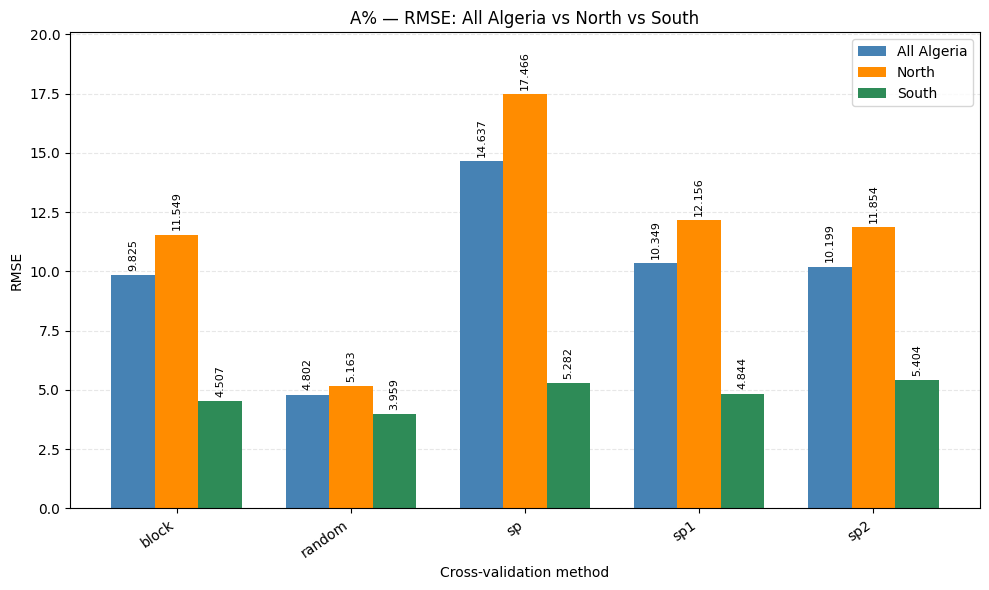

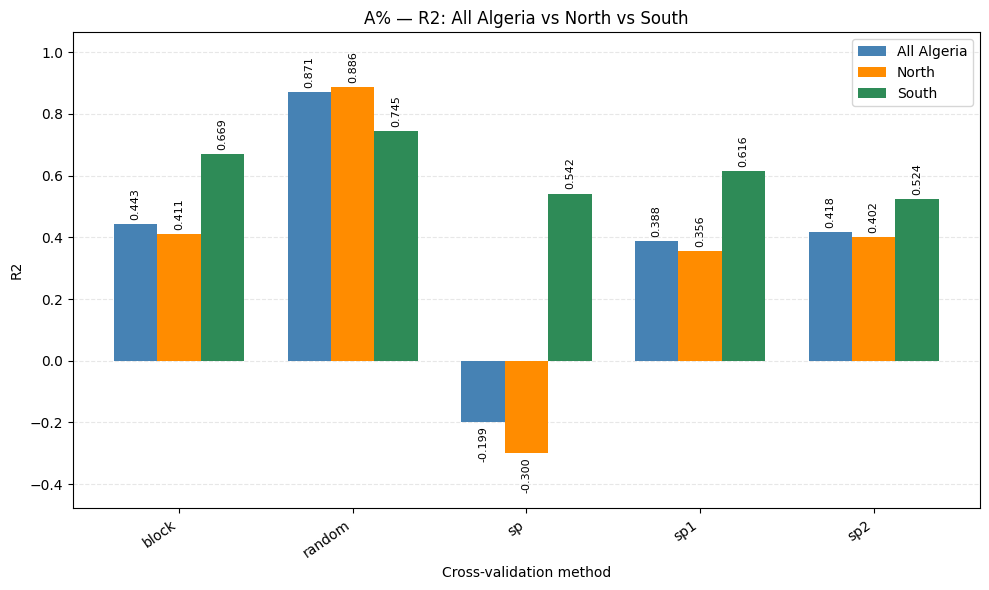

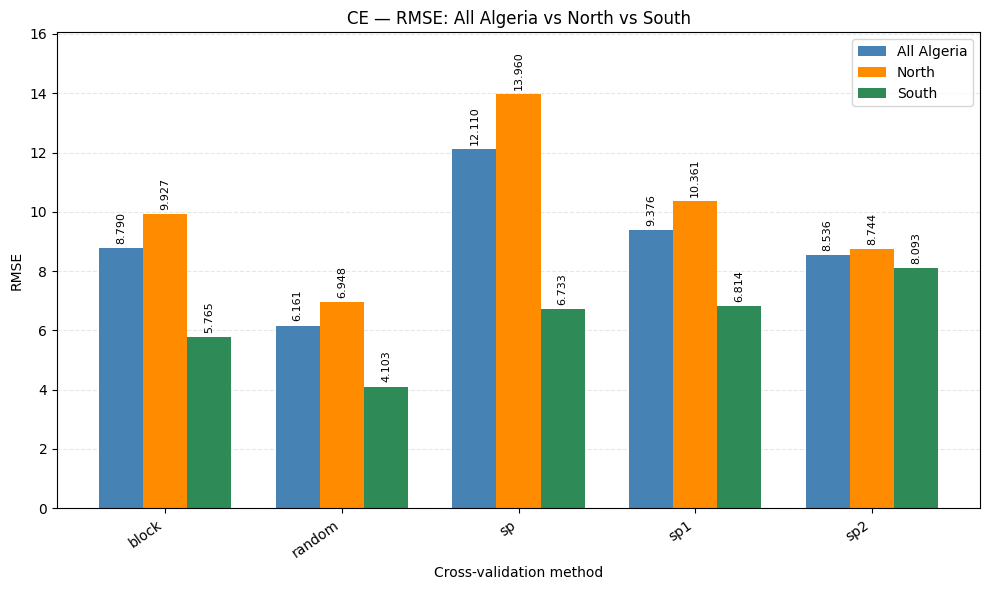

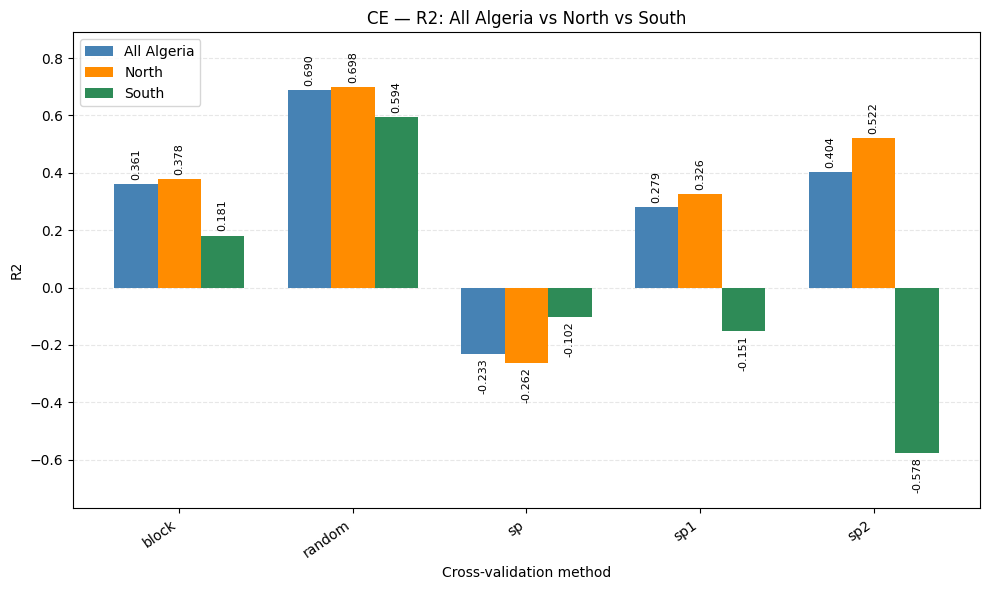

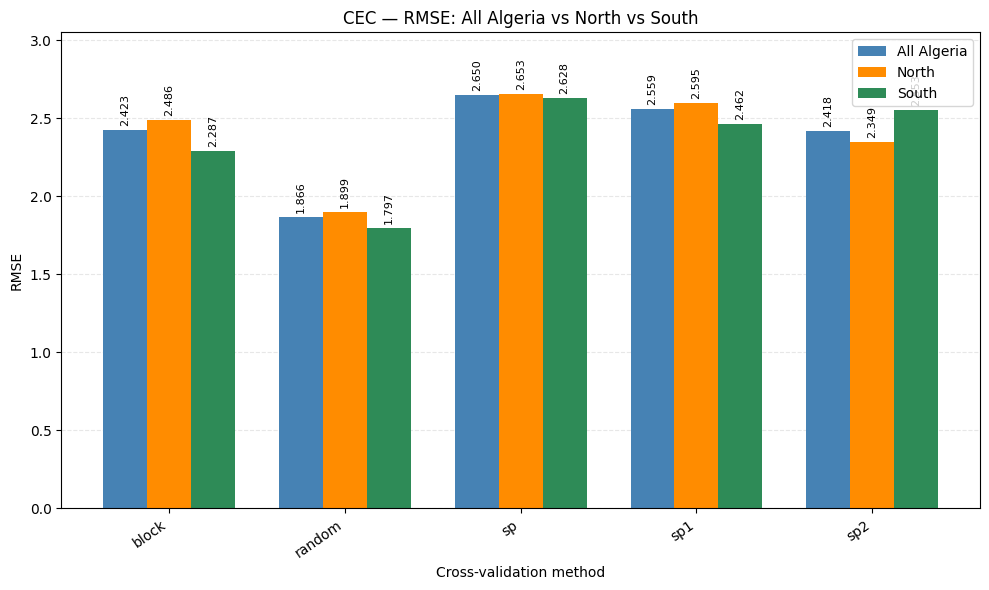

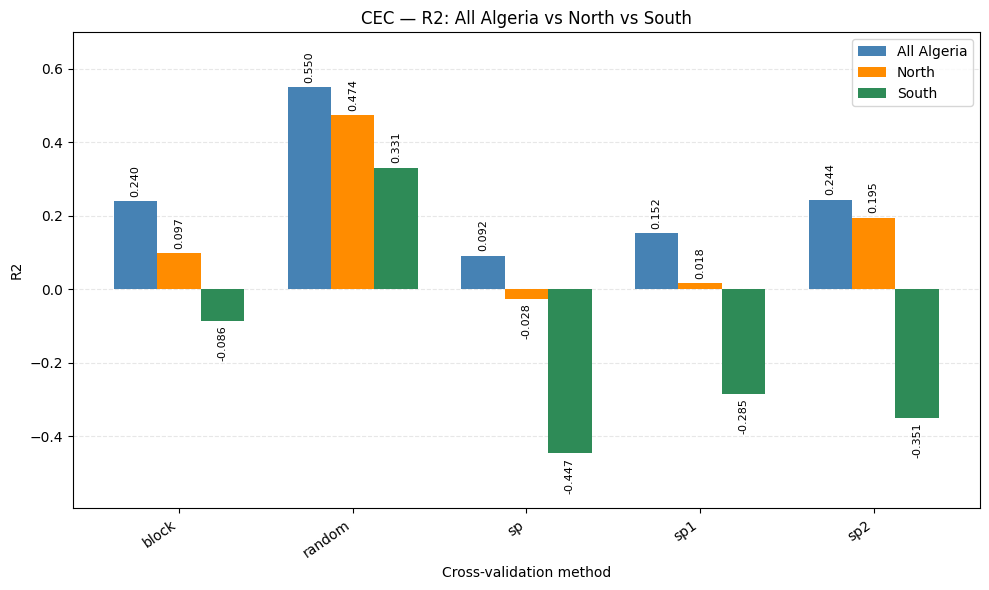

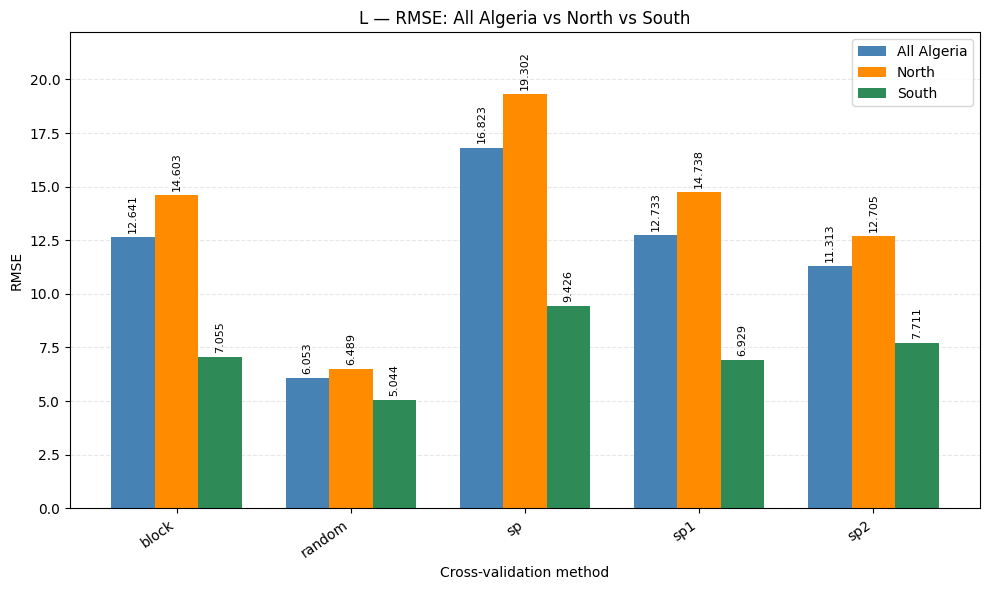

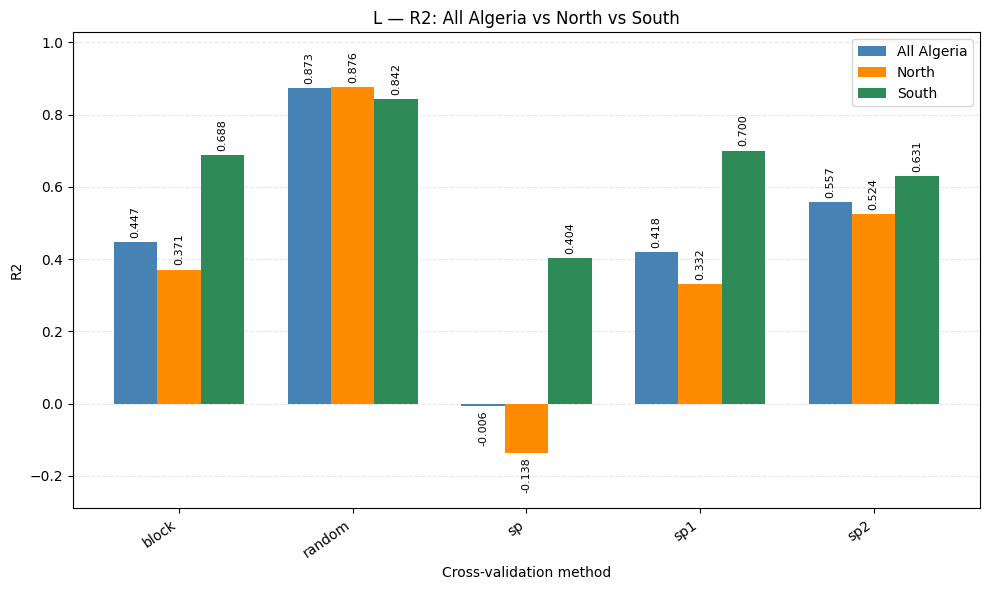

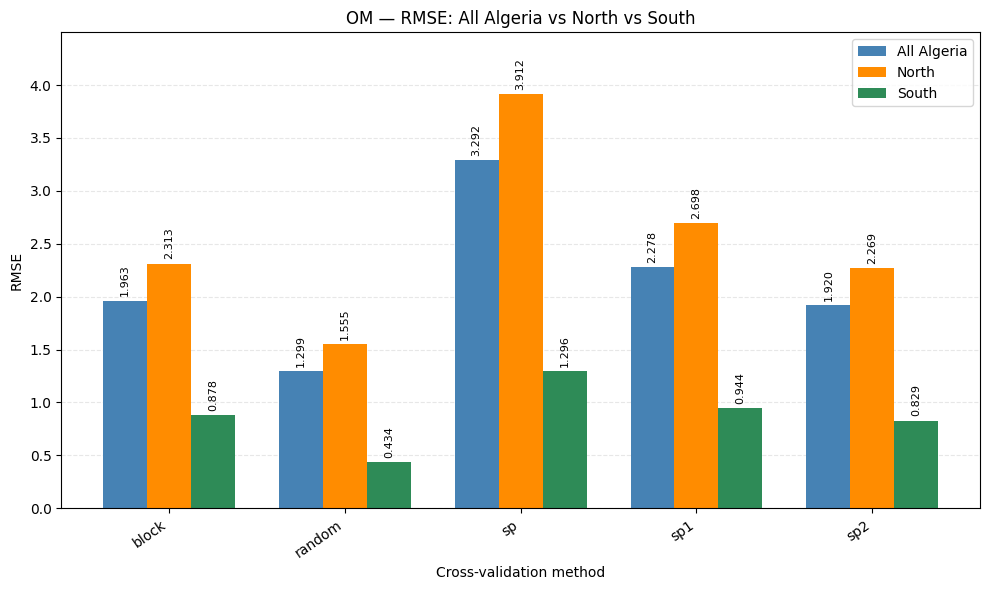

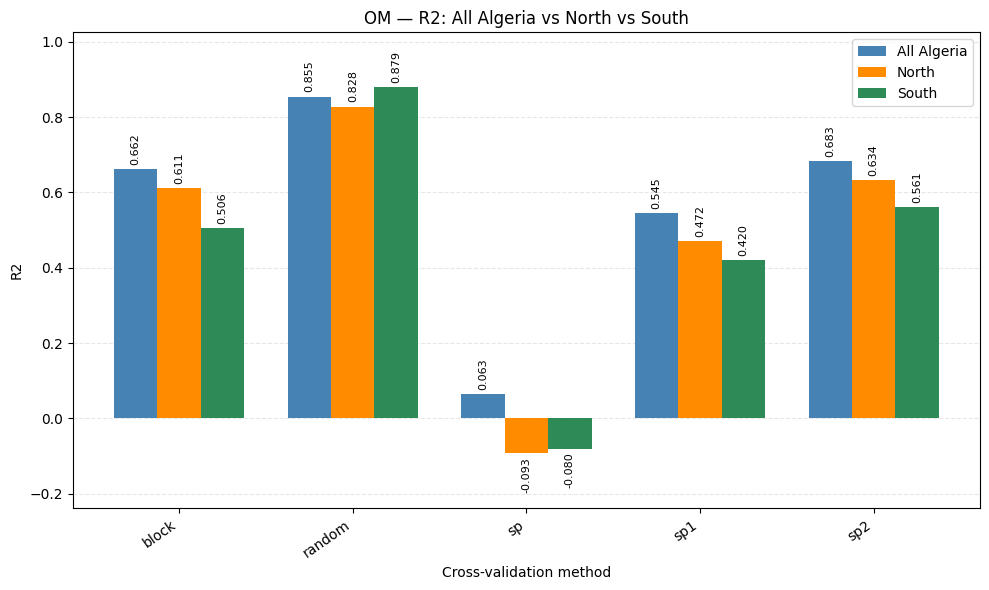

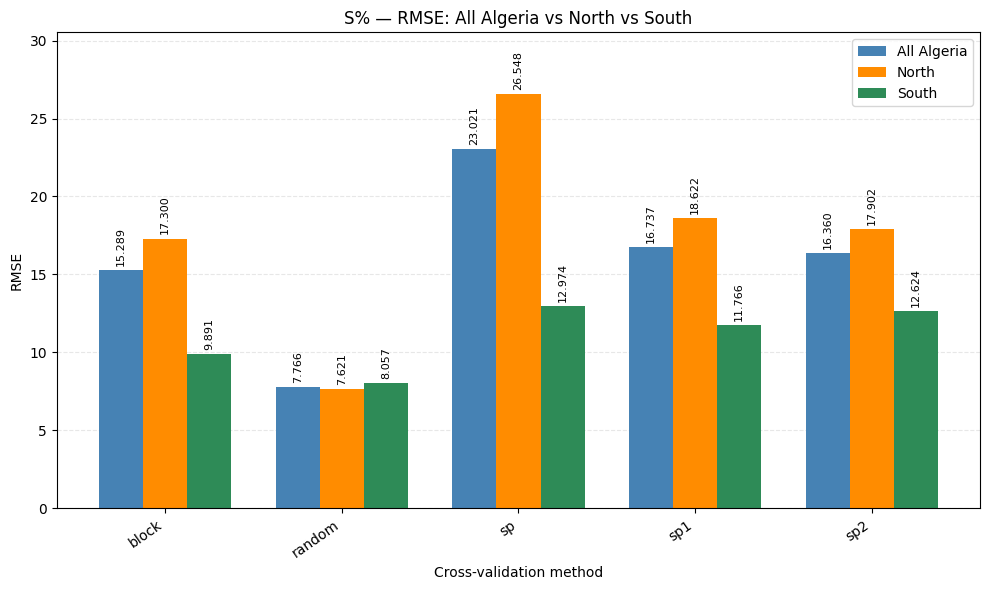

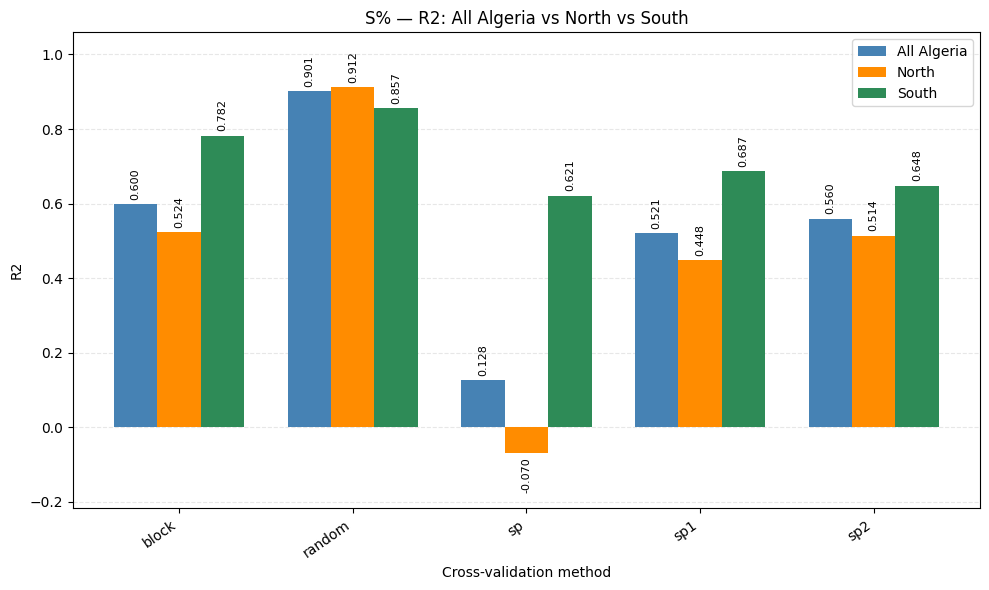

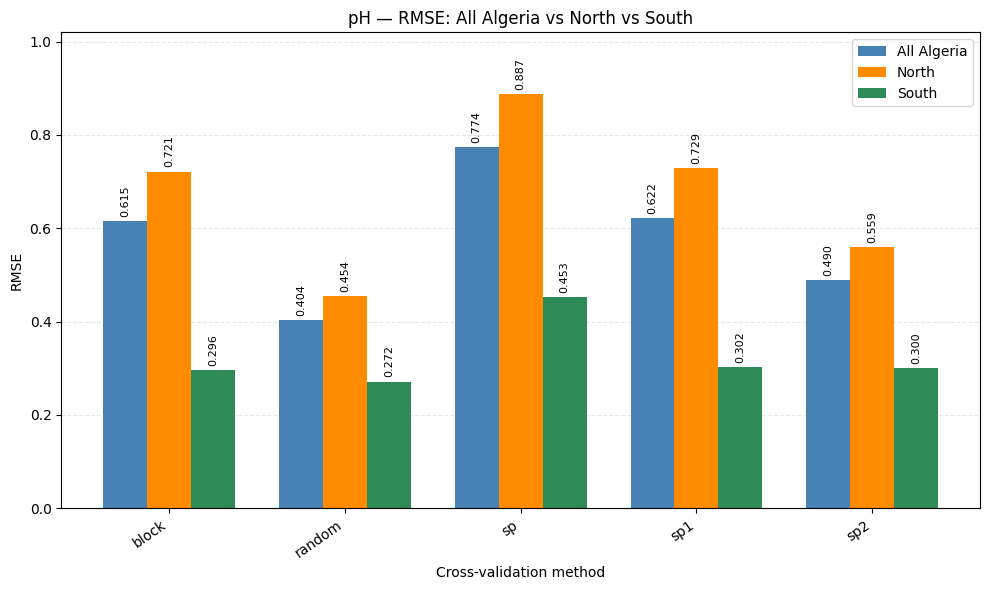

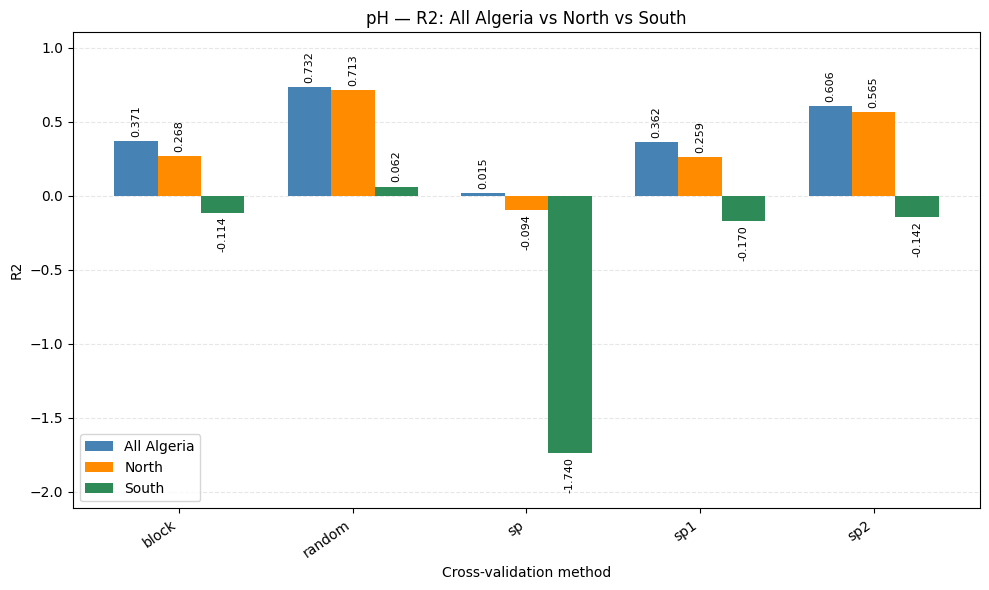

Plots saved in: cv_optuna_utcnn\test_best_random_on_spCV\all\plots_north_south_all


In [4]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
base_path = Path(f"cv_optuna_utcnn/test_best_random_on_spCV/{region}")
plot_dir = base_path / "plots_north_south_all"
plot_dir.mkdir(parents=True, exist_ok=True)

regions_order = ["all", "north", "south"]
metrics = ["RMSE", "R2"]

# Consistent region ordering and labels
region_labels = {
    "all": "All Algeria",
    "north": "North",
    "south": "South"
}

colors = {
    "all": "steelblue",
    "north": "darkorange",
    "south": "seagreen"
}
LATITUDE_BOUNDARY= 35.0

results_df = pd.read_csv(base_path / f"metrics_north_south_average_{LATITUDE_BOUNDARY}.csv")
for prop in sorted(results_df["soil_property"].unique()):

    prop_df = results_df[
        results_df["soil_property"] == prop
    ]

    cv_methods = sorted(prop_df["cv_method"].unique())

    for metric in metrics:

        # Rows = CV methods, columns = regions
        pivot = prop_df.pivot_table(
            index="cv_method",
            columns="region",
            values=metric,
            aggfunc="first"
        ).reindex(index=cv_methods, columns=regions_order)

        x = np.arange(len(cv_methods))
        width = 0.25

        fig, ax = plt.subplots(figsize=(
            max(10, len(cv_methods) * 1.5), 6
        ))

        for i, region in enumerate(regions_order):
            values = pivot[region].to_numpy(dtype=float)

            bars = ax.bar(
                x + (i - 1) * width,
                values,
                width,
                label=region_labels[region],
                color=colors[region]
            )

            # Display metric values above bars
            ax.bar_label(
                bars,
                fmt="%.3f",
                padding=3,
                fontsize=8,
                rotation=90
            )

        ax.set_xlabel("Cross-validation method")
        ax.set_ylabel(metric)
        ax.set_title(f"{prop} — {metric}: All Algeria vs North vs South")
        ax.set_xticks(x)
        ax.set_xticklabels(cv_methods, rotation=35, ha="right")
        ax.legend()
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        # Leave room for value labels
        ax.margins(y=0.15)
        fig.tight_layout()

        filename = f"{prop}_{metric}.png"
        fig.savefig(plot_dir / filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

print(f"Plots saved in: {plot_dir}")


In [12]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path
import math

# ============================================================
# CONFIGURATION
# ============================================================

LATITUDE_BOUNDARY = 35.0

plot_dir = base_path / "plots_north_south_all"
plot_dir.mkdir(parents=True, exist_ok=True)

results_df = pd.read_csv(
    base_path / f"metrics_north_south_average_{LATITUDE_BOUNDARY}.csv"
)

regions_order = ["all", "north", "south"]

region_labels = {
    "all": "All Algeria",
    "north": "North",
    "south": "South",
}

colors = {
    "all": "steelblue",
    "north": "darkorange",
    "south": "seagreen",
}

metrics = ["RMSE", "R2"]

preferred_cv_order = ["random", "sp2", "block", "sp1", "sp"]

# ============================================================
# PREPARE DATA
# ============================================================

results_df["region"] = results_df["region"].astype(str).str.lower()
results_df["cv_method"] = results_df["cv_method"].astype(str)

# Support different capitalization in the CSV
metric_columns = {col.lower(): col for col in results_df.columns}

properties = sorted(results_df["soil_property"].dropna().unique())
title_property_map = {prop: prop for prop in properties}  # Customize if needed
title_property_map['A%'] = 'clay%'
title_property_map['S%'] = 'sand%'
title_property_map['L'] = 'silt%'
title_property_map['CE'] = 'EC'
title_property_map['OM'] = 'SOM'

# ============================================================
# CREATE ONE INTERACTIVE FIGURE PER METRIC
# ============================================================

def plot_metric(metric):
    metric_col = metric_columns[metric.lower()]

    ncols = 2
    nrows = math.ceil(len(properties) / ncols)

    fig = make_subplots(
        rows=nrows,
        cols=ncols,
        subplot_titles=[title_property_map[prop] for prop in properties],
        horizontal_spacing=0.10,
        vertical_spacing=0.12,
    )

    for prop_idx, prop in enumerate(properties):
        row = prop_idx // ncols + 1
        col = prop_idx % ncols + 1

        prop_df = results_df[
            results_df["soil_property"] == prop
        ]

        available_methods = prop_df["cv_method"].dropna().unique().tolist()

        cv_methods = [
            method for method in preferred_cv_order
            if method in available_methods
        ]
        cv_methods += sorted(
            method for method in available_methods
            if method not in cv_methods
        )

        pivot = prop_df.pivot_table(
            index="cv_method",
            columns="region",
            values=metric_col,
            aggfunc="mean",
        ).reindex(
            index=cv_methods,
            columns=regions_order,
        )

        for region in regions_order:
            values = pivot[region].to_numpy(dtype=float)

            fig.add_trace(
                go.Bar(
                    x=cv_methods,
                    y=values,
                    name=region_labels[region],
                    legendgroup=region,
                    showlegend=(prop_idx == 0),
                    marker_color=colors[region],
                    text=[
                        f"{v:.3f}" if np.isfinite(v) else ""
                        for v in values
                    ],
                    textposition="outside",
                    textangle=-90,
                    cliponaxis=False,
                    hovertemplate=(
                        f"<b>Property:</b> {prop}"
                        "<br><b>CV method:</b> %{x}"
                        f"<br><b>Region:</b> {region_labels[region]}"
                        f"<br><b>{metric}:</b> %{{y:.4f}}"
                        "<extra></extra>"
                    ),
                ),
                row=row,
                col=col,
            )

        fig.update_xaxes(
            title_text="CV method",
            categoryorder="array",
            categoryarray=cv_methods,
            tickangle=-30,
            row=row,
            col=col,
        )

        # Independent y-axis limits for each property
        vals = pivot.to_numpy(dtype=float)
        vals = vals[np.isfinite(vals)]

        if vals.size:
            ymin, ymax = vals.min(), vals.max()
            spread = ymax - ymin
            padding = spread * 0.25 if spread > 0 else max(abs(ymin) * 0.1, 0.05)

            lower = min(0, ymin - padding)
            upper = max(0, ymax + padding)

            fig.update_yaxes(
                range=[lower, upper],
                title_text=metric,
                row=row,
                col=col,
            )

    fig.update_layout(
        title=dict(
            text=(
                f"{metric}: All Algeria vs North vs South"
                f"<br><sup>Latitude boundary = {LATITUDE_BOUNDARY}°N</sup>"
            ),
            x=0.5,
        ),
        barmode="group",
        template="plotly_white",
        height=360 * nrows,
        width=1400,
        legend=dict(
            title="Evaluation region",
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5,
        ),
        margin=dict(l=70, r=40, t=120, b=80),
        uniformtext_minsize=7,
        uniformtext_mode="hide",
    )

    filename = f"all_properties_{metric}_north_south.html"
    output_path = plot_dir / filename

    fig.write_html(output_path, include_plotlyjs="cdn")
    fig.write_image(plot_dir / f"all_properties_{metric}_north_south.png", scale=2)
    fig.show()

    print(f"Saved: {output_path}")


# ============================================================
# GENERATE TWO FIGURES
# ============================================================

for metric in metrics:
    plot_metric(metric)

print(f"\nInteractive plots saved in: {plot_dir}")

Saved: cv_optuna_utcnn\test_best_random_on_spCV\all\plots_north_south_all\all_properties_RMSE_north_south.html


Saved: cv_optuna_utcnn\test_best_random_on_spCV\all\plots_north_south_all\all_properties_R2_north_south.html

Interactive plots saved in: cv_optuna_utcnn\test_best_random_on_spCV\all\plots_north_south_all


## evaluate by regions : koppen

In [144]:
import xarray as xr

nc_path = "../Data/koppen_geiger_1p0.nc"  # Replace with your file path

ds = xr.open_dataset(nc_path)

print(ds)
print("\nVariables:", list(ds.data_vars))
print("Coordinates:", list(ds.coords))

for var in ds.data_vars:
    print(f"\nVariable: {var}")
    print(ds[var])

<xarray.Dataset> Size: 523kB
Dimensions:        (lon: 360, lat: 180)
Coordinates:
  * lon            (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * lat            (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -87.5 -88.5 -89.5
Data variables:
    kg_class       (lat, lon) float32 259kB ...
    kg_confidence  (lat, lon) float32 259kB ...
Attributes:
    history:  Created on 2025-10-21 08:18

Variables: ['kg_class', 'kg_confidence']
Coordinates: ['lon', 'lat']

Variable: kg_class
<xarray.DataArray 'kg_class' (lat: 180, lon: 360)> Size: 259kB
[64800 values with dtype=float32]
Coordinates:
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
Attributes:
    units:    

Variable: kg_confidence
<xarray.DataArray 'kg_confidence' (lat: 180, lon: 360)> Size: 259kB
[64800 values with dtype=float32]
Coordinates:
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr

# --------------------------------------------------
# Paths
# --------------------------------------------------
profiles_path = "../Data/unitask_data/dataset.csv"
nc_path = "../Data/koppen_geiger_1p0.nc"  # Replace with your file path
nc_path = "../Data/external_data/koppen_geiger_0p1.nc"
# --------------------------------------------------
# Load data
# --------------------------------------------------
profiles = pd.read_csv(profiles_path)
ds = xr.open_dataset(nc_path)

# Your profile coordinates
lon_col = "X"
lat_col = "Y"

# Check coordinates
print(ds.coords)

# --------------------------------------------------
# Extract nearest Köppen grid cell
# --------------------------------------------------
profile_lon = profiles[lon_col].to_numpy(dtype=float)
profile_lat = profiles[lat_col].to_numpy(dtype=float)

# Ensure coordinates are within the raster's longitude convention
profile_lon = ((profile_lon + 180) % 360) - 180

# Create coordinate arrays indexed by profile
lon_da = xr.DataArray(profile_lon, dims="profile")
lat_da = xr.DataArray(profile_lat, dims="profile")

# Extract class and confidence
sampled_class = ds["kg_class"].sel(
    lon=lon_da,
    lat=lat_da,
    method="nearest"
)

sampled_confidence = ds["kg_confidence"].sel(
    lon=lon_da,
    lat=lat_da,
    method="nearest"
)

profiles["koppen_code"] = np.asarray(sampled_class.values).ravel()
profiles["koppen_confidence"] = np.asarray(
    sampled_confidence.values
).ravel()

# Report results
print("\nKöppen class codes:")
print(profiles["koppen_code"].value_counts(dropna=False).sort_index())

print("\nConfidence statistics:")
print(profiles["koppen_confidence"].describe())

profiles.to_csv("../Data/unitask_data/soil_profiles_with_koppen_codes.csv", index=False)

Coordinates:
  * lon      (lon) float64 29kB -179.9 -179.8 -179.8 ... 179.7 179.8 179.9
  * lat      (lat) float64 14kB 89.95 89.85 89.75 89.65 ... -89.75 -89.85 -89.95

Köppen class codes:
koppen_code
0.0      2
4.0    288
5.0     21
6.0    834
7.0    460
8.0    551
Name: count, dtype: int64

Confidence statistics:
count    2156.000000
mean       83.399353
std        19.178066
min         0.000000
25%        72.000000
50%        88.000000
75%        99.000000
max       100.000000
Name: koppen_confidence, dtype: float64


In [173]:
print("Dataset attributes:")
print(ds.attrs)

print("\nClass variable attributes:")
print(ds["kg_class"].attrs)

print("\nUnique class codes:")
print(np.sort(profiles["koppen_code"].dropna().unique()))

print("\nUnique confidence values:")
print(np.sort(profiles["koppen_confidence"].dropna().unique())[:30])

Dataset attributes:
{'history': 'Created on 2025-10-21 08:16'}

Class variable attributes:
{'units': ''}

Unique class codes:
[0. 4. 5. 6. 7. 8.]

Unique confidence values:
[ 0. 51. 55. 56. 58. 60. 61. 65. 66. 67. 68. 69. 70. 71. 72. 73. 74. 75.
 76. 77. 78. 79. 80. 81. 82. 83. 84. 85. 86. 87.]


In [ ]:
# Decode numeric codes into Köppen classes
code_to_koppen = {
    0: "Csa",  # Csa: Tell-like, Mediterranean
    8: "Csa" , # Csa: Tell-like, Mediterranean
    6: "BSh",  # BSh: semi-arid steppe
    7: "BSk",  # BSk: semi-arid steppe
    4: "BWh",  # BWh: hot desert
    5: "BWk",  # BWk: cold desert
}

profiles["koppen_class"] = (
    profiles["koppen_code"]
    .round()
    .map(code_to_koppen)
)

# Provisional three-region grouping
koppen_to_region = {
    "Csa": "Tell (Mediterranean)",
    "BSh": "Tell (Mediterranean)",
    "BSk": "High plateaus (semi-arid steppe)",
    "BWh": "Sahara (arid desert)",
    "BWk": "High plateaus (semi-arid steppe)",
}

profiles["climate_region"] = profiles["koppen_class"].map(
    koppen_to_region
)

# Count profiles per region
print("\nProfile counts by region:")
print(
    profiles["climate_region"]
    .value_counts(dropna=False)
)

print("\nKöppen classes within each region:")
print(
    pd.crosstab(
        profiles["climate_region"],
        profiles["koppen_class"],
        margins=True
    )
)

# Save the results
profiles.to_csv(
    "../Data/unitask_data/soil_profiles_with_koppen_regions.csv",
    index=False
)


Profile counts by region:
climate_region
Tell (Mediterranean)                1385
High plateaus (semi-arid steppe)     481
Sahara (arid desert)                 288
NaN                                    2
Name: count, dtype: int64

Köppen classes within each region:
koppen_class                      BSh  BSk  BWh  BWk  Csa   All
climate_region                                                 
High plateaus (semi-arid steppe)    0  460    0   21    0   481
Sahara (arid desert)                0    0  288    0    0   288
Tell (Mediterranean)              834    0    0    0  551  1385
All                               834  460  288   21  551  2154


In [ ]:

import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score


# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

PROFILES_PATH = Path("../Data/unitask_data/soil_profiles_with_koppen_regions.csv")

# Point this to the folder containing random/, sp_k5_10000/, etc.
# Example: .../test_best_random_on_spCV/all/
RESULTS_ROOT = Path(
    "cv_optuna_utcnn/test_best_random_on_spCV/all"
)

OUTPUT_DIR = Path("cv_optuna_utcnn/test_best_random_on_spCV/all/Results_Koppen_Regions")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LON_COL = "X"
LAT_COL = "Y"

# Must match the names in your profiles CSV
REGION_COL = "koppen_class"

REGIONS = [
    "Tell (Mediterranean)",
    "High plateaus (semi-arid steppe)",
    "Sahara (arid desert)",
]

# Change these if your output folders use different names.
# The code also accepts folders such as output[A%], output_A%, etc.
# ============================================================
# 2. LOAD PROFILE REGIONS
# ============================================================

profiles = pd.read_csv(PROFILES_PATH)

required_columns = [LON_COL, LAT_COL, REGION_COL]
missing = [c for c in required_columns if c not in profiles.columns]

if missing:
    raise ValueError(
        f"Missing columns in profiles CSV: {missing}"
    )

profiles[REGION_COL] = profiles[REGION_COL].astype("string").str.strip()

print("Total profiles:", len(profiles))
print("\nProfiles by region:")
print(profiles[REGION_COL].value_counts(dropna=False))

# One Boolean mask per region.
# The mask order MUST match the first axis of the OOF arrays.
# One mask per evaluation group
region_masks = {
    "All Algeria": np.ones(len(profiles), dtype=bool),
    "Tell (Mediterranean)": (
        profiles[REGION_COL]
        .eq("Tell (Mediterranean)")
        .fillna(False)
        .to_numpy()
    ),
    "High plateaus (semi-arid steppe)": (
        profiles[REGION_COL]
        .eq("High plateaus (semi-arid steppe)")
        .fillna(False)
        .to_numpy()
    ),
    "Sahara (arid desert)": (
        profiles[REGION_COL]
        .eq("Sahara (arid desert)")
        .fillna(False)
        .to_numpy()
    ),
}

for region, mask in region_masks.items():
    print(f"{region}: {mask.sum()} profiles")



# ============================================================
# 3. PARSE CV METHOD NAMES
# ============================================================

def parse_cv_method(method_name):
    """
    Examples:
        random          -> random, None
        sp_k5_10000     -> sp, 10000
        sp1_k5_10000    -> sp1, 10000
        sp2_k5          -> sp2, None
        block_k5_10000  -> block, 10000
    """
    name = str(method_name).strip().lower()

    if name == "random":
        return "random", None

    match = re.fullmatch(
        r"(block|sp1|sp2|sp)_k\d+(?:_(\d+))?",
        name,
    )

    if match:
        method = match.group(1)
        threshold = (
            int(match.group(2))
            if match.group(2) is not None
            else None
        )
        return method, threshold

    return None, None


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def get_property_name(folder_name):
    """
    Handles names such as:
        outputA%
        output_A%
        output[A%]
        Output[pH]
        A%
    """
    name = str(folder_name).strip()

    name = re.sub(
        r"^output[_\s]*",
        "",
        name,
        flags=re.IGNORECASE,
    )

    name = name.strip("[]_ ")

    return name


def calculate_metrics(y_true, y_pred):
    """
    Calculates metrics after removing NaN/Inf pairs.
    Arrays may contain multiple depth values per profile.
    """
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: y_true={y_true.shape}, "
            f"y_pred={y_pred.shape}"
        )

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    y_true = y_true[valid]
    y_pred = y_pred[valid]

    if len(y_true) == 0:
        return {
            "n_values": 0,
            "rmse": np.nan,
            "r2": np.nan,
        }

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # R² is undefined with fewer than two observations.
    r2 = (
        r2_score(y_true, y_pred)
        if len(y_true) >= 2
        else np.nan
    )

    return {
        "n_values": len(y_true),
        "rmse": rmse,
        "r2": r2,
    }


# ============================================================
# 5. EVALUATE EVERY PROPERTY / CV METHOD / THRESHOLD
# ============================================================

results = []

if not RESULTS_ROOT.exists():
    raise FileNotFoundError(
        f"RESULTS_ROOT does not exist: {RESULTS_ROOT}"
    )

prediction_files = sorted(
    RESULTS_ROOT.rglob("y_pred_oof.npy")
)

if not prediction_files:
    raise FileNotFoundError(
        f"No y_pred_oof.npy files found under {RESULTS_ROOT}"
    )

for pred_path in prediction_files:

    # Expected layout:
    # RESULTS_ROOT / cv_method / output_property / y_pred_oof.npy
    property_folder = pred_path.parent
    method_folder = property_folder.parent

    cv_method_original = method_folder.name
    cv_method, threshold = parse_cv_method(
        cv_method_original
    )

    if cv_method is None:
        print(
            f"Skipping unrecognized method: "
            f"{cv_method_original}"
        )
        continue

    true_path = pred_path.parent / "y_true_oof.npy"

    if not true_path.exists():
        print(f"Missing true values: {true_path}")
        continue

    soil_property = get_property_name(
        property_folder.name
    )

    y_pred = np.load(pred_path)
    y_true = np.load(true_path)

    # --------------------------------------------------------
    # IMPORTANT: first array dimension must match profile order
    # --------------------------------------------------------
    if y_pred.shape != y_true.shape:
        raise ValueError(
            f"Prediction/true shape mismatch for {pred_path}\n"
            f"y_pred: {y_pred.shape}, y_true: {y_true.shape}"
        )

    if y_pred.shape[0] != len(profiles):
        raise ValueError(
            f"Profile alignment problem for {pred_path}\n"
            f"Array first dimension = {y_pred.shape[0]}, "
            f"number of profiles = {len(profiles)}.\n"
            "Do not apply the masks until the profile ordering "
            "or OOF sample indices have been aligned."
        )

    print(
        f"Evaluating property={soil_property}, "
        f"method={cv_method_original}, "
        f"shape={y_true.shape}"
    )

    # Evaluate each region using the SAME OOF predictions
    for region, mask in region_masks.items():

        n_profiles = int(mask.sum())

        if n_profiles == 0:
            continue

        # Index the profile axis first, then flatten the values.
        y_true_region = y_true[mask]
        y_pred_region = y_pred[mask]

        metrics = calculate_metrics(
            y_true_region,
            y_pred_region,
        )

        results.append({
            "soil_property": soil_property,
            "region": region,
            "cv_method_original": cv_method_original,
            "cv_method": cv_method,
            "threshold": threshold,
            "threshold_km": (
                threshold / 1000
                if threshold is not None
                else np.nan
            ),
            "n_profiles": n_profiles,
            "n_values": metrics["n_values"],
            "rmse": metrics["rmse"],
            "r2": metrics["r2"],
            "source_file": str(pred_path),
        })


# ============================================================
# 6. SAVE DETAILED METRICS BY THRESHOLD
# ============================================================

metrics_df = pd.DataFrame(results)

if metrics_df.empty:
    raise ValueError(
        "No metrics were generated. Check your paths and "
        "CV method folder names."
    )

metrics_path = OUTPUT_DIR / "metrics_by_koppen_region_threshold.csv"

metrics_df.to_csv(metrics_path, index=False)

print("\nDetailed metrics saved to:")
print(metrics_path)

print(metrics_df.head())


# ============================================================
# 7. AVERAGE THRESHOLD-BASED SPATIAL METHODS
# ============================================================

# These methods have multiple thresholds to average.
THRESHOLD_METHODS = {"block", "sp1", "sp"}

# Each property / region / CV method will have one row.
GROUP_COLS = [
    "soil_property",
    "region",
    "cv_method",
]

# Average metrics across thresholds.
# Random and SP2 will also be retained as one row each
# if they each have one experiment per property.
averaged_df = (
    metrics_df
    .groupby(GROUP_COLS, as_index=False)
    .agg(
        rmse=("rmse", "mean"),
        r2=("r2", "mean"),
        n_thresholds=("threshold", "count"),
        n_profiles=("n_profiles", "first"),
        n_values=("n_values", "first"),
    )
)

# Number of distinct non-null thresholds used in each group.
threshold_counts = (
    metrics_df
    .dropna(subset=["threshold"])
    .groupby(GROUP_COLS)["threshold"]
    .nunique()
    .rename("n_distinct_thresholds")
    .reset_index()
)

averaged_df = averaged_df.merge(
    threshold_counts,
    on=GROUP_COLS,
    how="left",
)

averaged_df["n_distinct_thresholds"] = (
    averaged_df["n_distinct_thresholds"]
    .fillna(0)
    .astype(int)
)

averaged_path = (
    OUTPUT_DIR / "metrics_by_koppen_region_averaged.csv"
)

averaged_df.to_csv(averaged_path, index=False)

print("\nAveraged metrics saved to:")
print(averaged_path)

print(
    averaged_df.sort_values(
        ["soil_property", "region", "cv_method"]
    ).to_string(index=False)
)


Total profiles: 2156

Profiles by region:
climate_region
Tell (Mediterranean)                1387
High plateaus (semi-arid steppe)     481
Sahara (arid desert)                 288
Name: count, dtype: Int64
All Algeria: 2156 profiles
Tell (Mediterranean): 1387 profiles
High plateaus (semi-arid steppe): 481 profiles
Sahara (arid desert): 288 profiles
Evaluating property=A%, method=block_k5_10000, shape=(2156, 1)
Evaluating property=CE, method=block_k5_10000, shape=(2156, 1)
Evaluating property=CEC, method=block_k5_10000, shape=(2156, 1)
Evaluating property=L, method=block_k5_10000, shape=(2156, 1)
Evaluating property=OM, method=block_k5_10000, shape=(2156, 1)
Evaluating property=pH, method=block_k5_10000, shape=(2156, 1)
Evaluating property=S%, method=block_k5_10000, shape=(2156, 1)
Evaluating property=A%, method=block_k5_20000, shape=(2156, 1)
Evaluating property=CE, method=block_k5_20000, shape=(2156, 1)
Evaluating property=CEC, method=block_k5_20000, shape=(2156, 1)
Evaluating propert

OSError: [Errno 22] Invalid argument: 'cv_optuna_utcnn\\test_best_random_on_spCV\\all\\Results_Koppen_Regions\\plots\\RMSE_All_Algeria_vs_Climate_Regions.png'

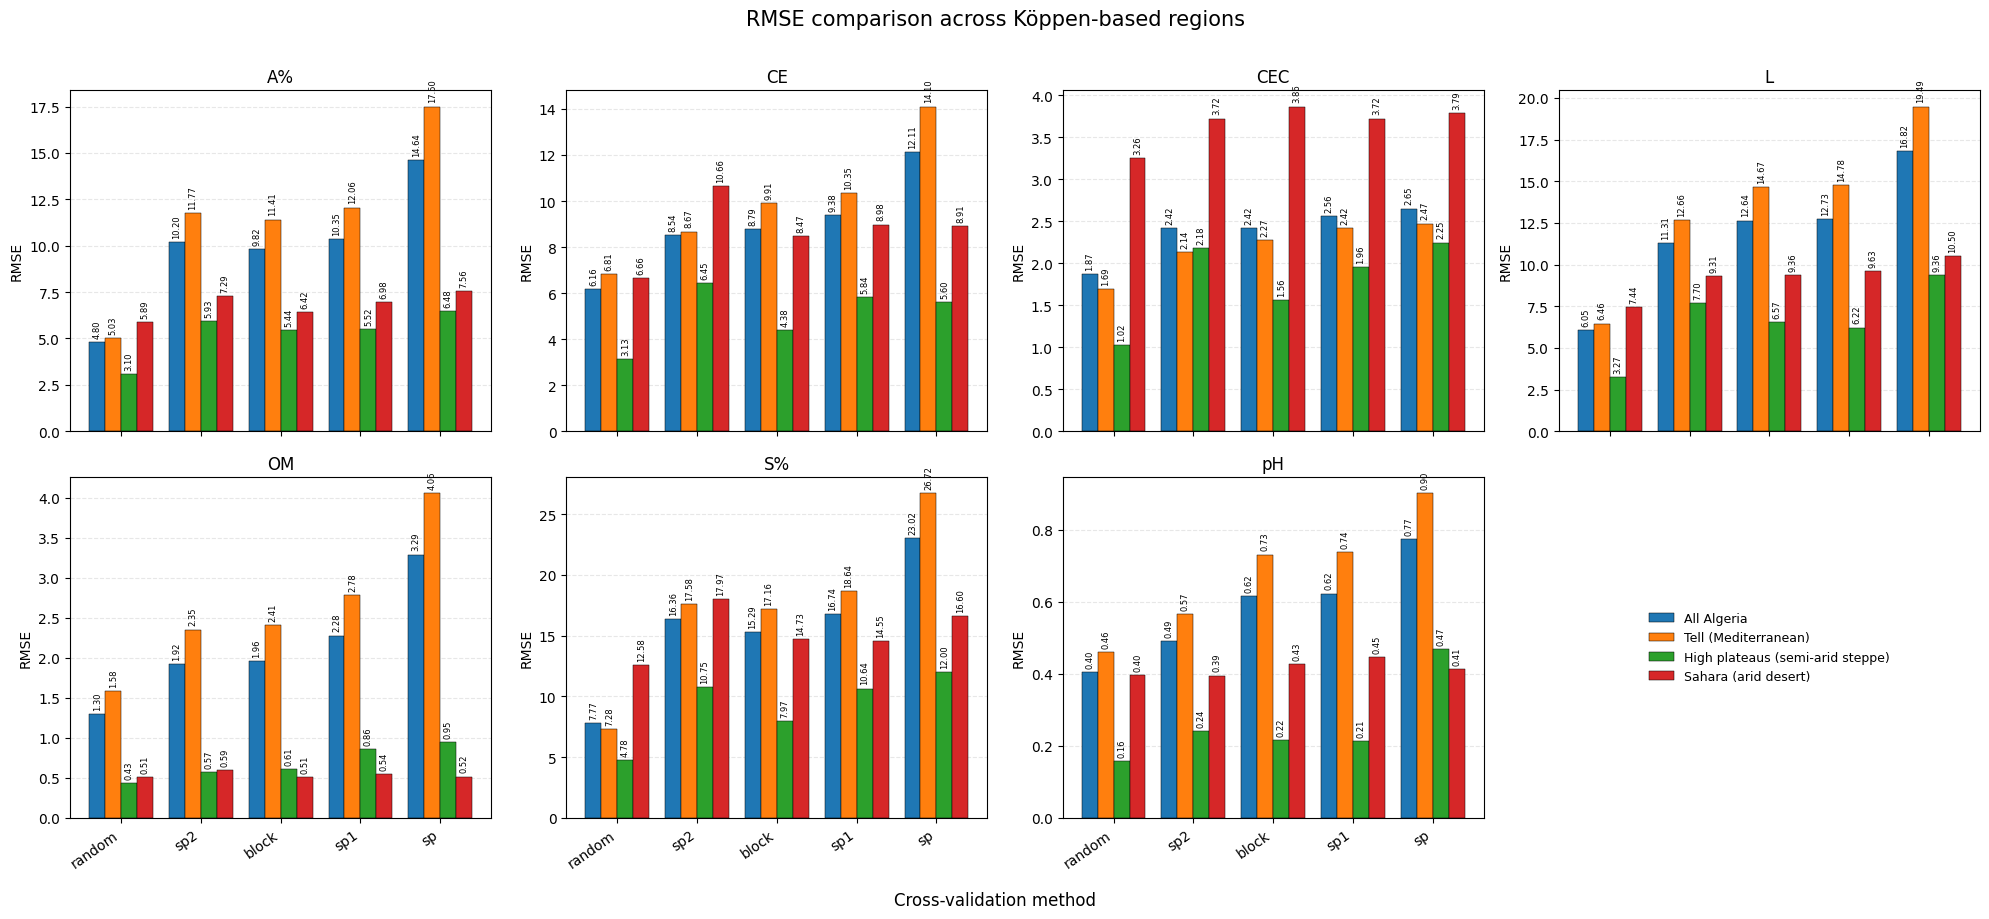

In [149]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# SETTINGS
# ============================================================

PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

props = ["A%", "CE", "CEC", "L", "OM", "S%", "pH"]

region_order = [
    "All Algeria",
    "Tell (Mediterranean)",
    "High plateaus (semi-arid steppe)",
    "Sahara (arid desert)",
]

cv_order = ["random", "sp2", "block", "sp1", "sp"]

# Use only categories present in the data
region_order = [
    r for r in region_order
    if r in averaged_df["region"].unique()
]

cv_order = [
    cv for cv in cv_order
    if cv in averaged_df["cv_method"].unique()
]

# ============================================================
# PLOT FUNCTION
# ============================================================

def plot_region_comparison(
    df,
    metric,
    ylabel,
    filename,
    higher_is_better=False,
):
    fig, axes = plt.subplots(
        2, 4,
        figsize=(20, 9),
        sharex=True,
    )
    axes = axes.flatten()

    x = np.arange(len(cv_order))
    n_regions = len(region_order)
    total_width = 0.8
    bar_width = total_width / n_regions

    for i, prop in enumerate(props):
        ax = axes[i]

        subset = df[
            df["soil_property"].astype(str).eq(prop)
        ].copy()

        for j, region in enumerate(region_order):
            region_data = (
                subset[subset["region"].eq(region)]
                .set_index("cv_method")
                .reindex(cv_order)
            )

            values = region_data[metric].to_numpy(dtype=float)

            offsets = (
                j - (n_regions - 1) / 2
            ) * bar_width

            bars = ax.bar(
                x + offsets,
                values,
                width=bar_width,
                label=region,
                edgecolor="black",
                linewidth=0.35,
            )

            # Label bars when a value exists
            for bar, value in zip(bars, values):
                if np.isfinite(value):
                    ax.annotate(
                        f"{value:.2f}",
                        (
                            bar.get_x() + bar.get_width() / 2,
                            bar.get_height(),
                        ),
                        xytext=(0, 3 if value >= 0 else -11),
                        textcoords="offset points",
                        ha="center",
                        va="bottom" if value >= 0 else "top",
                        fontsize=6,
                        rotation=90,
                    )

        if metric == "r2":
            ax.axhline(0, color="grey", linewidth=1)

        ax.set_title(prop)
        ax.set_xticks(x)
        ax.set_xticklabels(cv_order, rotation=35, ha="right")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

    # Hide unused subplot
    axes[-1].axis("off")

    # Shared legend in the unused panel
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(
        handles,
        labels,
        loc="center",
        fontsize=9,
        frameon=False,
    )

    fig.suptitle(
        f"{ylabel} comparison across Köppen-based regions",
        fontsize=15,
        y=1.01,
    )
    fig.supxlabel("Cross-validation method")
    fig.tight_layout()

    fig.savefig(
        PLOT_DIR / filename,
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()


# ============================================================
# RMSE: lower is better
# ============================================================

plot_region_comparison(
    df=averaged_df,
    metric="rmse",
    ylabel="RMSE",
    filename="RMSE_All_Algeria_vs_Climate_Regions.png",
)

# ============================================================
# R²: higher is better
# ============================================================

plot_region_comparison(
    df=averaged_df,
    metric="r2",
    ylabel="R²",
    filename="R2_All_Algeria_vs_Climate_Regions.png",
    higher_is_better=True,
)

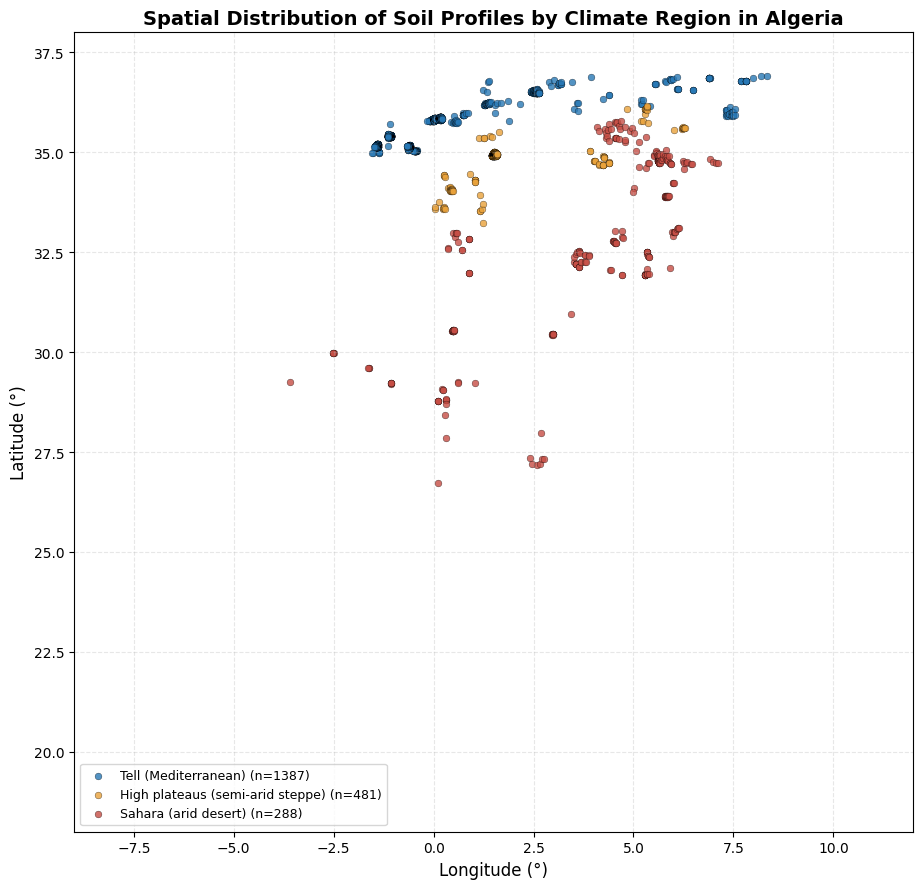

climate_region
Tell (Mediterranean)                1387
High plateaus (semi-arid steppe)     481
Sahara (arid desert)                 288
Name: count, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# Configuration
# --------------------------------------------------
CSV_PATH = "../Data/unitask_data/soil_profiles_with_koppen_regions.csv"

LON_COL = "X"
LAT_COL = "Y"
REGION_COL = "climate_region"

REGION_ORDER = [
    "Tell (Mediterranean)",
    "High plateaus (semi-arid steppe)",
    "Sahara (arid desert)",
]

COLORS = {
    "Tell (Mediterranean)": "#2878B5",
    "High plateaus (semi-arid steppe)": "#E9A23B",
    "Sahara (arid desert)": "#C64E45",
}

# --------------------------------------------------
# Load and validate the profiles
# --------------------------------------------------
profiles = pd.read_csv(CSV_PATH)

required_cols = [LON_COL, LAT_COL, REGION_COL]
missing = [c for c in required_cols if c not in profiles.columns]

if missing:
    raise ValueError(f"Missing columns in CSV: {missing}")

profiles[LON_COL] = pd.to_numeric(profiles[LON_COL], errors="coerce")
profiles[LAT_COL] = pd.to_numeric(profiles[LAT_COL], errors="coerce")

profiles = profiles.dropna(subset=[LON_COL, LAT_COL]).copy()

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 9))

for region in REGION_ORDER:
    subset = profiles[profiles[REGION_COL] == region]

    ax.scatter(
        subset[LON_COL],
        subset[LAT_COL],
        c=COLORS[region],
        label=f"{region} (n={len(subset)})",
        s=24,
        alpha=0.8,
        edgecolors="black",
        linewidths=0.25,
    )

# Profiles without a recognized region
unassigned = profiles[~profiles[REGION_COL].isin(REGION_ORDER)]

if not unassigned.empty:
    ax.scatter(
        unassigned[LON_COL],
        unassigned[LAT_COL],
        color="lightgray",
        label=f"Unassigned (n={len(unassigned)})",
        s=24,
        edgecolors="black",
        linewidths=0.25,
    )

ax.set_xlim(-9, 12)
ax.set_ylim(18, 38)
ax.set_xlabel("Longitude (°)", fontsize=12)
ax.set_ylabel("Latitude (°)", fontsize=12)
ax.set_title(
    "Spatial Distribution of Soil Profiles by Climate Region in Algeria",
    fontsize=14,
    fontweight="bold",
)

ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower left", fontsize=9, frameon=True)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig("soil_profiles_by_climate_region.png", dpi=300, bbox_inches="tight")
plt.show()

# Print profile counts
print(profiles[REGION_COL].value_counts(dropna=False))

<xarray.Dataset> Size: 52MB
Dimensions:        (lon: 3600, lat: 1800)
Coordinates:
  * lon            (lon) float64 29kB -179.9 -179.8 -179.8 ... 179.7 179.8 179.9
  * lat            (lat) float64 14kB 89.95 89.85 89.75 ... -89.75 -89.85 -89.95
Data variables:
    kg_class       (lat, lon) float32 26MB ...
    kg_confidence  (lat, lon) float32 26MB ...
Attributes:
    history:  Created on 2025-10-21 08:16


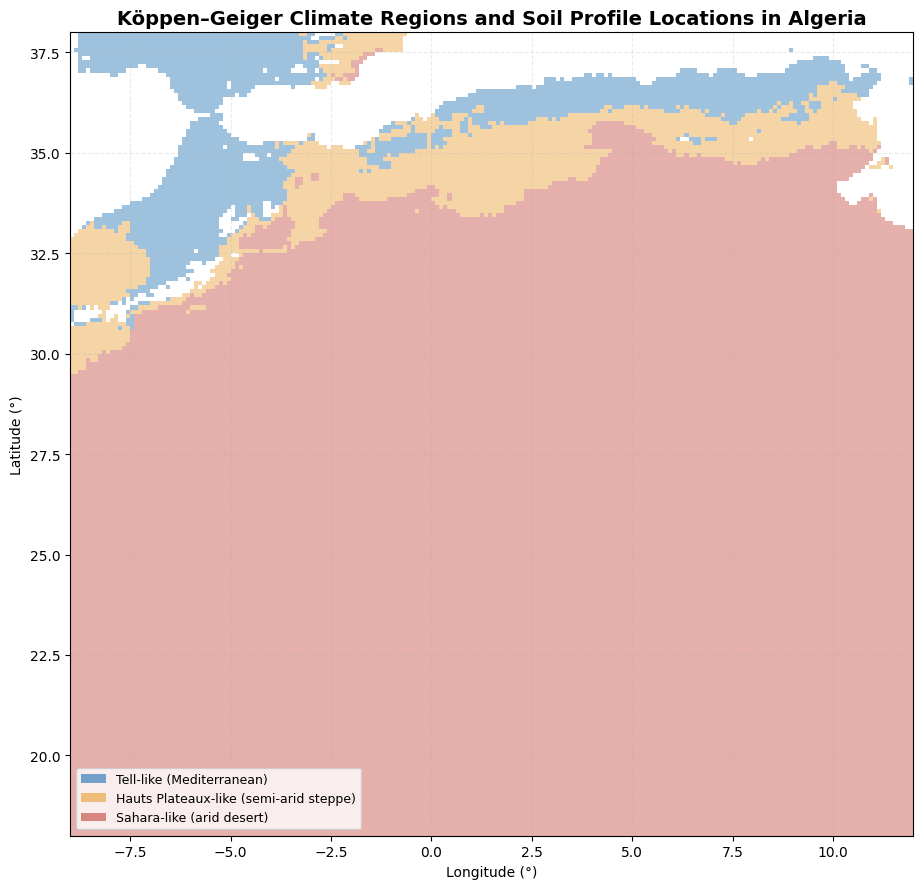

In [ ]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --------------------------------------------------
# Paths
# --------------------------------------------------
NETCDF_PATH = "../Data/koppen_geiger_0p1.nc"

# --------------------------------------------------
# Load profiles and raster
# --------------------------------------------------
profiles = pd.read_csv(CSV_PATH)

ds = xr.open_dataset(NETCDF_PATH)
kg = ds["kg_class"]

# If needed, inspect the actual variable and coordinate names:
print(ds)

# --------------------------------------------------
# Provisional Köppen class -> regional grouping
# Verify codes against the dataset's legend.
# --------------------------------------------------
class_to_region = {
    # 8: 1,  # Csa -> Tell-like
    # 7: 2,  # BSk -> Hauts Plateaux-like
    # 4: 3,  # BWh -> Sahara-like
    # 5: 3,  # BWk -> Sahara-like, provisional

    8: 1,  # Csa: Tell-like, Mediterranean
    6: 2,  # BSh: semi-arid steppe
    7: 2,  # BSk: semi-arid steppe
    4: 3,  # BWh: hot desert
    5: 3,  # BWk: cold desert
}

region_names = {
    1: "Tell-like (Mediterranean)",
    2: "Hauts Plateaux-like (semi-arid steppe)",
    3: "Sahara-like (arid desert)",
}

region_colors = {
    1: "#2878B5",
    2: "#E9A23B",
    3: "#C64E45",
}

# Group raster classes into three regional categories
region_grid = xr.full_like(kg, np.nan, dtype=float)

for climate_class, region_code in class_to_region.items():
    region_grid = xr.where(
        kg == climate_class,
        region_code,
        region_grid
    )

# Crop to Algeria and nearby surroundings
region_grid = region_grid.sel(
    lon=slice(-9, 12),
    lat=slice(38, 18)  # latitude is descending in your raster
)

# --------------------------------------------------
# Plot raster and profiles
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 9))

cmap = ListedColormap([
    region_colors[1],
    region_colors[2],
    region_colors[3],
])

# Mask unknown raster classes
masked_grid = np.ma.masked_invalid(region_grid.values)

mesh = ax.pcolormesh(
    region_grid["lon"].values,
    region_grid["lat"].values,
    masked_grid,
    cmap=cmap,
    vmin=0.5,
    vmax=3.5,
    shading="nearest",
    alpha=0.45,
)

# Overlay profiles
for region_code, region_name in region_names.items():
    subset = profiles[profiles["climate_region"] == region_name]

    ax.scatter(
        subset["X"],
        subset["Y"],
        color=region_colors[region_code],
        label=f"{region_name} (n={len(subset)})",
        s=22,
        edgecolors="black",
        linewidths=0.35,
        zorder=3,
    )

# Legend
legend_items = [
    Patch(
        facecolor=region_colors[code],
        alpha=0.65,
        label=name
    )
    for code, name in region_names.items()
]

ax.legend(handles=legend_items, loc="lower left", fontsize=9)

ax.set_xlim(-9, 12)
ax.set_ylim(18, 38)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.set_title(
    "Köppen–Geiger Climate Regions and Soil Profile Locations in Algeria",
    fontsize=14,
    fontweight="bold",
)
ax.grid(True, linestyle="--", alpha=0.25)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()
plt.savefig(
    "algeria_climate_regions_and_soil_profiles.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

ds.close()

In [ ]:

# Install if needed:
# pip install pandas plotly geopandas requests

import json
import requests
import pandas as pd
import geopandas as gpd
import plotly.express as px
import plotly.graph_objects as go

# --------------------------------------------------
# Paths and column names
# --------------------------------------------------
CSV_PATH = "../Data/unitask_data/soil_profiles_with_koppen_regions.csv"

# Change CLASS_COL to the column containing labels such as Csa, BSk, BWh
LON_COL = "X"
LAT_COL = "Y"
CLASS_COL = "koppen_class"

GEOJSON_URL = (
    "https://raw.githubusercontent.com/yasserstudio/geoalgeria/"
    "main/packages/dataset/data/geojson/wilaya-boundaries.geojson"
)

# --------------------------------------------------
# Load soil profiles
# --------------------------------------------------
df = pd.read_csv(CSV_PATH)

df[LON_COL] = pd.to_numeric(df[LON_COL], errors="coerce")
df[LAT_COL] = pd.to_numeric(df[LAT_COL], errors="coerce")

df = df.dropna(subset=[LON_COL, LAT_COL, CLASS_COL]).copy()
df[CLASS_COL] = df[CLASS_COL].astype(str).str.strip()

# Exclude missing / unclassified codes, if applicable
df = df[~df[CLASS_COL].isin([0, "0", "0.0", "nan", "None", ""])]

# --------------------------------------------------
# Load wilaya boundaries
# --------------------------------------------------
response = requests.get(GEOJSON_URL, timeout=60)
response.raise_for_status()

geojson = response.json()
wilayas = gpd.GeoDataFrame.from_features(
    geojson["features"],
    crs="EPSG:4326"
)

print("GeoJSON columns:", wilayas.columns.tolist())
print("Number of boundary features:", len(wilayas))


# Inspect the codes first
print(sorted(wilayas["code"].astype(str).unique()))

# Wilaya code -> French name
# This lookup covers the 58-wilaya administrative division.
wilaya_names = {
    "01": "Adrar",
    "02": "Chlef",
    "03": "Laghouat",
    "04": "Oum El Bouaghi",
    "05": "Batna",
    "06": "Béjaïa",
    "07": "Biskra",
    "08": "Béchar",
    "09": "Blida",
    "10": "Bouira",
    "11": "Tamanrasset",
    "12": "Tébessa",
    "13": "Tlemcen",
    "14": "Tiaret",
    "15": "Tizi Ouzou",
    "16": "Alger",
    "17": "Djelfa",
    "18": "Jijel",
    "19": "Sétif",
    "20": "Saïda",
    "21": "Skikda",
    "22": "Sidi Bel Abbès",
    "23": "Annaba",
    "24": "Guelma",
    "25": "Constantine",
    "26": "Médéa",
    "27": "Mostaganem",
    "28": "M'Sila",
    "29": "Mascara",
    "30": "Ouargla",
    "31": "Oran",
    "32": "El Bayadh",
    "33": "Illizi",
    "34": "Bordj Bou Arréridj",
    "35": "Boumerdès",
    "36": "El Tarf",
    "37": "Tindouf",
    "38": "Tissemsilt",
    "39": "El Oued",
    "40": "Khenchela",
    "41": "Souk Ahras",
    "42": "Tipaza",
    "43": "Mila",
    "44": "Aïn Defla",
    "45": "Naâma",
    "46": "Aïn Témouchent",
    "47": "Ghardaïa",
    "48": "Relizane",
    "49": "Timimoun",
    "50": "Bordj Badji Mokhtar",
    "51": "Ouled Djellal",
    "52": "Béni Abbès",
    "53": "In Salah",
    "54": "In Guezzam",
    "55": "Touggourt",
    "56": "Djanet",
    "57": "El M'Ghair",
    "58": "El Meniaa",
    "59": "Aflou",
    "60": "Barika",
    "61": "El Kantara",
    "62": "Bir El Ater",
    "63": "El Aricha",
    "64": "Ksar Chellala",
    "65": "Aïn Oussera",
    "66": "Messaad",
    "67": "Ksar El Boukhari",
    "68": "Bou Saâda",
    "69": "El Abiodh Sidi Cheikh",
}

# Normalize codes such as 1, 1.0, or "01" to two-digit strings
def normalize_code(value):
    return str(int(float(value))).zfill(2)

wilayas["code_norm"] = wilayas["code"].apply(normalize_code)
wilayas["wilaya_name"] = wilayas["code_norm"].map(wilaya_names)

# Check for codes that do not match the lookup
unknown_codes = wilayas.loc[
    wilayas["wilaya_name"].isna(), "code_norm"
].unique()

if len(unknown_codes):
    print("Codes without names:", unknown_codes)
    wilayas["wilaya_name"] = wilayas["wilaya_name"].fillna(
        "Wilaya " + wilayas["code_norm"]
    )


# Find the wilaya name field automatically
possible_name_cols = [
    "name", "NAME_1", "name_fr", "wilaya", "nom",
    "NAME", "shapeName", "wilaya_name"
]

name_col = next(
    (col for col in possible_name_cols if col in wilayas.columns),
    None
)

if name_col is None:
    raise ValueError(
        "Could not identify the wilaya name field. "
        f"Available fields: {wilayas.columns.tolist()}"
    )

# If name is stored as a dictionary/object, extract a readable label
wilayas["wilaya_name"] = wilayas[name_col].apply(
    lambda x: (
        x.get("fr") or x.get("name") or x.get("en")
        if isinstance(x, dict)
        else str(x)
    )
)

# Keep Algeria's approximate bounding box
wilayas = wilayas.cx[-9:12, 18:38].copy()

# --------------------------------------------------
# Build interactive Plotly map
# --------------------------------------------------
fig = go.Figure()

# Wilaya boundaries
for _, row in wilayas.iterrows():
    geom = row.geometry
    if geom is None:
        continue

    polygons = (
        list(geom.geoms)
        if geom.geom_type == "MultiPolygon"
        else [geom]
    )

    for polygon in polygons:
        x, y = polygon.exterior.xy
        fig.add_trace(go.Scattergeo(
            lon=list(x),
            lat=list(y),
            mode="lines",
            line=dict(color="gray", width=0.7),
            hoverinfo="text",
            text=str(row["wilaya_name"]),
            showlegend=False,
        ))

# Wilaya labels at representative points
label_points = wilayas.copy()
label_points["label_point"] = label_points.geometry.representative_point()
label_points["label_lon"] = label_points["label_point"].x
label_points["label_lat"] = label_points["label_point"].y

fig.add_trace(go.Scattergeo(
    lon=label_points["label_lon"],
    lat=label_points["label_lat"],
    text=label_points["wilaya_name"],
    mode="text",
    textfont=dict(size=8, color="#333333"),
    hovertemplate="%{text}<extra>Wilaya</extra>",
    showlegend=False,
))

# Soil profiles, grouped by Köppen class
for climate_class in sorted(df[CLASS_COL].unique()):
    subset = df[df[CLASS_COL] == climate_class]

    fig.add_trace(go.Scattergeo(
        lon=subset[LON_COL],
        lat=subset[LAT_COL],
        mode="markers",
        name=climate_class,
        marker=dict(size=6, opacity=0.85),
        customdata=subset[[LON_COL, LAT_COL]].to_numpy(),
        hovertemplate=(
            f"<b>Köppen class: {climate_class}</b><br>"
            "Longitude: %{customdata[0]:.4f}<br>"
            "Latitude: %{customdata[1]:.4f}"
            "<extra>Soil profile</extra>"
        ),
    ))

fig.update_geos(
    lonaxis_range=[-9, 12],
    lataxis_range=[18, 38],
    showcountries=True,
    showcoastlines=True,
    showland=True,
    landcolor="rgb(248,248,245)",
    countrycolor="black",
    coastlinecolor="black",
    resolution=50,
    projection_type="mercator",
)

fig.update_layout(
    title="Algerian Soil Profiles by Köppen–Geiger Class and Wilaya",
    template="plotly_white",
    height=850,
    legend_title="Köppen–Geiger class",
    margin=dict(l=10, r=10, t=60, b=10),
)

fig.show()
fig.write_html("algeria_profiles_wilayas_koppen.html")


GeoJSON columns: ['geometry', 'code']
Number of boundary features: 69
['1', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '2', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '3', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '4', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '5', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '6', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '7', '8', '9']


In [ ]:

import re
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score


# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

PROFILES_PATH = Path("../Data/unitask_data/soil_profiles_with_koppen_regions.csv")

RESULTS_ROOT = Path(
    "cv_optuna_utcnn/test_best_random_on_spCV/all"
)

OUTPUT_DIR = RESULTS_ROOT / "Results_Climate_Comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LON_COL = "X"
LAT_COL = "Y"

# Evaluate both classification schemes
CLASSIFICATION_COLUMNS = {
    # "climate_region": "climate_region",
    "koppen_class": "koppen_class",
}

# If True, include classes/regions found in the CSV automatically.
# Missing labels are excluded from their respective subsets.
INCLUDE_ALL_ALGERIA = True


# ============================================================
# 2. LOAD PROFILES AND BUILD MASKS
# ============================================================

profiles = pd.read_csv(PROFILES_PATH)

for col in [LON_COL, LAT_COL]:
    if col not in profiles.columns:
        print(f"Warning: coordinate column {col!r} not found.")

for classification_type, col in CLASSIFICATION_COLUMNS.items():
    if col not in profiles.columns:
        raise ValueError(
            f"Column {col!r} required for {classification_type!r} "
            f"not found. Available columns: {profiles.columns.tolist()}"
        )

    profiles[col] = profiles[col].astype("string").str.strip()
    profiles[col] = profiles[col].replace("", pd.NA)

print("Total profiles:", len(profiles))

# A mask dictionary for each classification scheme
all_masks = {}

for classification_type, col in CLASSIFICATION_COLUMNS.items():

    masks = {}

    if INCLUDE_ALL_ALGERIA:
        masks["All Algeria"] = np.ones(len(profiles), dtype=bool)

    # Automatically create a mask for every label in the column
    labels = sorted(profiles[col].dropna().unique().tolist())

    for label in labels:
        masks[str(label)] = (
            profiles[col]
            .eq(label)
            .fillna(False)
            .to_numpy(dtype=bool)
        )

    all_masks[classification_type] = masks

    print(f"\n{'=' * 60}")
    print(f"Classification: {classification_type}")
    print(f"Column: {col}")
    print("Counts:")
    print(profiles[col].value_counts(dropna=False).to_string())

    for label, mask in masks.items():
        print(f"  {label}: {mask.sum()} profiles")


# ============================================================
# 3. PARSE CV METHOD NAMES
# ============================================================

def parse_cv_method(method_name):
    """
    Examples:
        random          -> random, None
        sp_k5_10000     -> sp, 10000
        sp1_k5_10000    -> sp1, 10000
        sp2_k5          -> sp2, None
        block_k5_10000  -> block, 10000
    """
    name = str(method_name).strip().lower()

    if name == "random":
        return "random", None

    match = re.fullmatch(
        r"(block|sp1|sp2|sp)_k\d+(?:_(\d+))?",
        name,
    )

    if match:
        method = match.group(1)
        threshold = (
            int(match.group(2))
            if match.group(2) is not None
            else None
        )
        return method, threshold

    return None, None


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def get_property_name(folder_name):
    """
    Handles:
        outputA%
        output_A%
        output[A%]
        Output[pH]
        A%
    """
    name = str(folder_name).strip()
    name = re.sub(
        r"^output[_\s]*",
        "",
        name,
        flags=re.IGNORECASE,
    )
    return name.strip("[]_ ")


def calculate_metrics(y_true, y_pred):
    """
    Calculates pooled RMSE and R² across all finite observations
    in the selected profile subset and all available depths.
    """
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    if y_true.shape != y_pred.shape:
        raise ValueError(
            f"Shape mismatch: y_true={y_true.shape}, "
            f"y_pred={y_pred.shape}"
        )

    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]

    if len(y_true) == 0:
        return {"n_values": 0, "rmse": np.nan, "r2": np.nan}

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred) if len(y_true) >= 2 else np.nan

    return {
        "n_values": len(y_true),
        "rmse": rmse,
        "r2": r2,
    }


# ============================================================
# 5. EVALUATE EACH CLASSIFICATION SCHEME
# ============================================================

if not RESULTS_ROOT.exists():
    raise FileNotFoundError(
        f"RESULTS_ROOT does not exist: {RESULTS_ROOT}"
    )

prediction_files = sorted(
    RESULTS_ROOT.rglob("y_pred_oof.npy")
)

if not prediction_files:
    raise FileNotFoundError(
        f"No y_pred_oof.npy files found under {RESULTS_ROOT}"
    )

results = []

for pred_path in prediction_files:

    # Expected layout:
    # RESULTS_ROOT / cv_method / output_property / y_pred_oof.npy
    property_folder = pred_path.parent
    method_folder = property_folder.parent

    cv_method_original = method_folder.name
    cv_method, threshold = parse_cv_method(cv_method_original)

    if cv_method is None:
        print(f"Skipping unrecognized method: {cv_method_original}")
        continue

    true_path = property_folder / "y_true_oof.npy"

    if not true_path.exists():
        print(f"Missing true values: {true_path}")
        continue

    soil_property = get_property_name(property_folder.name)

    y_pred = np.load(pred_path)
    y_true = np.load(true_path)

    if y_pred.shape != y_true.shape:
        raise ValueError(
            f"Prediction/true shape mismatch: {pred_path}\n"
            f"Prediction: {y_pred.shape}; true: {y_true.shape}"
        )

    if y_pred.shape[0] != len(profiles):
        raise ValueError(
            f"Profile alignment problem: {pred_path}\n"
            f"Array profiles={y_pred.shape[0]}, "
            f"CSV profiles={len(profiles)}.\n"
            "Align the profile order before applying masks."
        )

    print(
        f"Evaluating {soil_property} | {cv_method_original} "
        f"| shape={y_true.shape}"
    )

    # Evaluate each classification scheme separately
    for classification_type, masks in all_masks.items():

        for label, mask in masks.items():

            n_profiles = int(mask.sum())
            if n_profiles == 0:
                continue

            metrics = calculate_metrics(
                y_true[mask],
                y_pred[mask],
            )

            results.append({
                "classification_type": classification_type,
                "classification_label": label,
                "soil_property": soil_property,
                "cv_method_original": cv_method_original,
                "cv_method": cv_method,
                "threshold": threshold,
                "threshold_km": (
                    threshold / 1000
                    if threshold is not None
                    else np.nan
                ),
                "n_profiles": n_profiles,
                "n_values": metrics["n_values"],
                "rmse": metrics["rmse"],
                "r2": metrics["r2"],
                "source_file": str(pred_path),
            })


# ============================================================
# 6. SAVE DETAILED METRICS
# ============================================================

metrics_df = pd.DataFrame(results)

if metrics_df.empty:
    raise ValueError("No metrics generated. Check paths and CV names.")

detailed_path = OUTPUT_DIR / "metrics_by_class_threshold.csv"
metrics_df.to_csv(detailed_path, index=False)

print("\nDetailed results saved:", detailed_path)


# Also save separate detailed CSVs for convenience
for classification_type in CLASSIFICATION_COLUMNS:
    subset = metrics_df[
        metrics_df["classification_type"] == classification_type
    ]
    path = OUTPUT_DIR / f"metrics_{classification_type}_by_threshold.csv"
    subset.to_csv(path, index=False)
    print("Saved:", path)


# ============================================================
# 7. AVERAGE THRESHOLD-BASED METHODS
# ============================================================

GROUP_COLS = [
    "classification_type",
    "classification_label",
    "soil_property",
    "cv_method",
]

averaged_df = (
    metrics_df
    .groupby(GROUP_COLS, as_index=False)
    .agg(
        rmse=("rmse", "mean"),
        r2=("r2", "mean"),
        n_experiments=("cv_method_original", "count"),
        n_distinct_thresholds=("threshold", "nunique"),
        n_profiles=("n_profiles", "first"),
        n_values=("n_values", "first"),
    )
)

# For random/SP2, there may be one experiment and no threshold.
averaged_path = OUTPUT_DIR / "metrics_by_class_averaged.csv"
averaged_df.to_csv(averaged_path, index=False)

print("\nAveraged results saved:", averaged_path)

for classification_type in CLASSIFICATION_COLUMNS:
    subset = averaged_df[
        averaged_df["classification_type"] == classification_type
    ]

    path = OUTPUT_DIR / f"metrics_{classification_type}_averaged.csv"
    subset.to_csv(path, index=False)
    print("Saved:", path)

print("\nCombined averaged metrics:")
print(
    averaged_df.sort_values(
        ["classification_type", "soil_property",
         "classification_label", "cv_method"]
    ).to_string(index=False)
)


Total profiles: 2156

Classification: koppen_class
Column: koppen_class
Counts:
koppen_class
BSh     834
Csa     551
BSk     460
BWh     288
BWk      21
<NA>      2
  All Algeria: 2156 profiles
  BSh: 834 profiles
  BSk: 460 profiles
  BWh: 288 profiles
  BWk: 21 profiles
  Csa: 551 profiles
Evaluating A% | block_k5_10000 | shape=(2156, 1)
Evaluating CE | block_k5_10000 | shape=(2156, 1)
Evaluating CEC | block_k5_10000 | shape=(2156, 1)
Evaluating L | block_k5_10000 | shape=(2156, 1)
Evaluating OM | block_k5_10000 | shape=(2156, 1)
Evaluating pH | block_k5_10000 | shape=(2156, 1)
Evaluating S% | block_k5_10000 | shape=(2156, 1)
Evaluating A% | block_k5_20000 | shape=(2156, 1)
Evaluating CE | block_k5_20000 | shape=(2156, 1)
Evaluating CEC | block_k5_20000 | shape=(2156, 1)
Evaluating L | block_k5_20000 | shape=(2156, 1)
Evaluating OM | block_k5_20000 | shape=(2156, 1)
Evaluating pH | block_k5_20000 | shape=(2156, 1)
Evaluating S% | block_k5_20000 | shape=(2156, 1)
Evaluating A% | block

In [11]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from pathlib import Path
import math

# ============================================================
# CONFIGURATION
# ============================================================

INPUT_CSV = Path(
    "cv_optuna_utcnn/test_best_random_on_spCV/all/Results_Climate_Comparison/metrics_by_class_averaged.csv"
)

OUTPUT_DIR = Path(
    "cv_optuna_utcnn/test_best_random_on_spCV/all/Results_Climate_Comparison/Results_Climate_Comparison/combined_plots"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PROPERTIES = ["A%", "CE", "CEC", "L", "OM", "S%", "pH"]
title_property_map = {prop: prop for prop in properties}  # Customize if needed
title_property_map['A%'] = 'clay%'
title_property_map['S%'] = 'sand%'
title_property_map['L'] = 'silt%'
title_property_map['CE'] = 'EC'
title_property_map['OM'] = 'SOM'

CV_ORDER = ["random", "sp2", "block", "sp1", "sp"]

# Set True to include the overall Algeria metrics as another bar.
INCLUDE_ALL_ALGERIA = True

# ============================================================
# LOAD DATA
# ============================================================

df = pd.read_csv(INPUT_CSV)

# Keep only the expected properties
df = df[df["soil_property"].isin(PROPERTIES)].copy()

if not INCLUDE_ALL_ALGERIA:
    df = df[df["classification_label"] != "All Algeria"].copy()

# Standardize CV method names and keep the desired order
df["cv_method"] = df["cv_method"].astype(str).str.lower()

# Add any unexpected CV methods at the end rather than dropping them
extra_methods = sorted(set(df["cv_method"]) - set(CV_ORDER))
method_order = CV_ORDER + extra_methods

# Classification scheme order and display names
SCHEMES = [
    #  ("climate_region", "Geography regions"), 
      ("koppen_class", "Köppen classes"),
]

# Distinct colors for the categories, consistent across properties
COLOR_PALETTE = [
    "#4472C4", "#ED7D31", "#70AD47", "#A5A5A5",
    "#8064A2", "#FFC000", "#5B9BD5", "#C00000",
    "#00A6A6", "#E377C2",
]

# ============================================================
# CREATE ONE FIGURE PER METRIC
# ============================================================

def plot_metric(metric, metric_title, filename):
    ncols = 2
    nrows = math.ceil(len(PROPERTIES) / ncols)

    fig = make_subplots(
        rows=nrows,
        cols=ncols,
        subplot_titles=[title_property_map.get(prop, prop) for prop in PROPERTIES],
        shared_xaxes=False,
        vertical_spacing=0.10,
        horizontal_spacing=0.08,
    )

    # One legend entry per classification label across the whole figure
    legend_seen = set()

    for i, prop in enumerate(PROPERTIES):
        row = i // ncols + 1
        col = i % ncols + 1

        prop_df = df[df["soil_property"] == prop]

        for scheme, scheme_title in SCHEMES:
            scheme_df = prop_df[
                prop_df["classification_type"] == scheme
            ]

            if scheme_df.empty:
                continue

            labels = scheme_df["classification_label"].dropna().unique()

            # Put "All Algeria" first, then sort the remaining labels
            labels = sorted(
                labels,
                key=lambda x: (
                    str(x).lower() != "all algeria",
                    str(x).lower()
                )
            )

            for label_idx, label in enumerate(labels):
                label_df = scheme_df[
                    scheme_df["classification_label"] == label
                ]

                # Average duplicate entries for the same property,
                # class, and CV method if any remain in the CSV.
                values = (
                    label_df.groupby("cv_method")[metric]
                    .mean()
                    .reindex(method_order)
                )

                # Prefix labels so the two classification schemes
                # remain distinguishable in the legend.
                legend_name = f"{scheme_title}: {label}"
                show_legend = legend_name not in legend_seen
                legend_seen.add(legend_name)

                color = COLOR_PALETTE[
                    label_idx % len(COLOR_PALETTE)
                ]

                # Use a distinct dash pattern for the two schemes.
                # Bars stay grouped at each CV method.
                fig.add_trace(
                    go.Bar(
                        x=method_order,
                        y=values.to_numpy(),
                        name=legend_name,
                        legendgroup=legend_name,
                        showlegend=show_legend,
                        marker_color=color,
                        opacity=1.0 if scheme == "climate_region" else 0.55,
                        marker_pattern_shape=(
                            "" if scheme == "climate_region" else "/"
                        ),
                        offsetgroup=f"{scheme}_{label}",
                        alignmentgroup="soil_properties",
                        customdata=np.array(
                            [[scheme_title, label, method] for method in method_order],
                            dtype=object
                        ),
                        hovertemplate=(
                            "<b>Property:</b> " + prop +
                            "<br><b>CV method:</b> %{x}" +
                            "<br><b>Classification:</b> %{customdata[0]}" +
                            "<br><b>Class:</b> %{customdata[1]}" +
                            "<br><b>Metric:</b> %{y:.4f}" +
                            "<extra></extra>"
                        ),
                    ),
                    row=row,
                    col=col,
                )

        fig.update_xaxes(
            title_text="CV method",
            categoryorder="array",
            categoryarray=method_order,
            tickangle=-25,
            row=row,
            col=col,
        )

        fig.update_yaxes(
            title_text=metric.upper(),
            row=row,
            col=col,
        )

    fig.update_layout(
        title=dict(
            text=f"{metric_title} by CV method and climate classification",
            x=0.5,
        ),
        barmode="group",
        height=360 * nrows,
        width=1400,
        template="plotly_white",
        legend=dict(
            title="Classification scheme / class",
            orientation="v",
            yanchor="top",
            y=1,
            xanchor="left",
            x=1.02,
        ),
        margin=dict(l=70, r=320, t=100, b=80),
    )

    output_path = OUTPUT_DIR / filename
    fig.write_html(output_path, include_plotlyjs="cdn")
    fig.write_image(output_path.with_suffix(".png"), scale=2, engine="kaleido")
    fig.show()

    print(f"Saved: {output_path}")


# ============================================================
# GENERATE ONLY TWO FIGURES
# ============================================================

plot_metric("rmse", "RMSE", f"RMSE_all_properties_{SCHEMES[0][0]}.html")
plot_metric("r2", "R²", f"R2_all_properties_{SCHEMES[0][0]}.html")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_16844\3443392280.py:204: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




Saved: cv_optuna_utcnn\test_best_random_on_spCV\all\Results_Climate_Comparison\Results_Climate_Comparison\combined_plots\RMSE_all_properties_koppen_class.html


C:\Users\ASUS\AppData\Local\Temp\ipykernel_16844\3443392280.py:204: DeprecationWarning:


Support for the 'engine' argument is deprecated and will be removed after September 2025.
Kaleido will be the only supported engine at that time.




Saved: cv_optuna_utcnn\test_best_random_on_spCV\all\Results_Climate_Comparison\Results_Climate_Comparison\combined_plots\R2_all_properties_koppen_class.html
